# Tuolumne snowpatch — end-of-season snow cover

All data is precomputed and lives in `/scratch/dlhogan/ess-project-data/geospatial-data/snowpatch_fsca`.
Nothing here downloads or reprocesses imagery; it just loads CSVs and plots.

**What the record is.** Landsat Collection-2 L2, path 042 / row 034 (the only WRS
tile that fully covers the basin), 1985–2025. Binary NDSI snow classification per
30 m pixel. For each year we take the **minimum** over an **Aug 1 – Oct 10** window —
the minimum is immune both to cloud contamination and to transient early-October
snowfall, so it isolates *persistent* snow.

Snow area is **extrapolated over masked pixels**: `A = Σ_bands fSCA_band × Area_band`.
Counting snow only inside valid pixels undercounts by ~2×, because the masked
pixels are preferentially the shaded, snowier ones.

**Three tiers** (the terrain-shadow decision is the dominant uncertainty):

| tier | mask | role |
|---|---|---|
| `A_strict` | cloud + cloud-shadow (QA bits 1,2,3,4) | lower bound — removes the shaded pockets where late-season snow survives |
| `A_shadow` | keeps terrain shadow (bits 1,2,3) + `green>0.05` guard | **primary** for an end-of-season record |
| `A_aso` | `A_shadow` × ASO factor on bands 7–8 (1.19 / 1.77) | upper — matched to airborne ASO at SWE > 0.25 m |

`f_*` are the same quantities divided by HRU 2's area (8.611 km²): *"if all the
basin's persistent snow were gathered into the snowpatch HRU, what fraction of it
would be covered"*. HRU 2 is a conceptual store, not the literal footprint of the snow.


In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

DATA = Path("/scratch/dlhogan/ess-project-data/geospatial-data/snowpatch_fsca")
A_HRU2 = 8.611236          # km2, Tuolumne HRU 2 (3679 m, north-facing)
BASIN  = 774.5             # km2

eos   = pd.read_csv(DATA/"eos_final.csv", index_col="year", parse_dates=["date"])
pub   = pd.read_csv(DATA/"published_glacier_snowpatch_area.csv", comment="#").set_index("year")
peak  = pd.read_csv(DATA/"model_hru2_peak_swe.csv", index_col="year").peak_swe_mm
scene = pd.read_csv(DATA/"scenes_by_band3.csv", parse_dates=["date"])   # every scene

# The annual value is the MINIMUM across usable scenes in the window. With only
# one or two scenes there is effectively no minimum being taken, so those years
# are biased HIGH. Flag them rather than drop them.
eos["few_scenes"] = eos.n_scenes <= 2   # NB: do not name this "sparse" (pandas accessor)

print(f"annual record : {len(eos)} years, {eos.index.min()}-{eos.index.max()}")
print(f"scenes/yr     : median {eos.n_scenes.median():.0f}, min {eos.n_scenes.min():.0f}, max {eos.n_scenes.max():.0f}")
print(f"sparse years  : {sorted(eos.index[eos.few_scenes])}  "
      f"(1 scene: {sorted(eos.index[eos.n_scenes==1])})")
print(f"scene table   : {len(scene)} scenes, {(scene.status=='ok').sum()} usable")
print(f"published     : {len(pub)} years")
eos[["date","A_strict","A_shadow","A_aso","f_shadow"]].head()

annual record : 41 years, 1985-2025
scenes/yr     : median 6, min 1, max 9
sparse years  : [1990, 1991, 1992]  (1 scene: [1992])
scene table   : 368 scenes, 330 usable
published     : 14 years


,date,A_strict,A_shadow,A_aso,f_shadow
year,,,,,
1985,1985-08-11,0.972265,1.524979,2.137740,0.177092
1986,1986-09-15,1.374325,2.724456,3.837219,0.316384
1987,1987-09-18,0.291403,0.843793,1.113344,0.097987
1988,1988-10-06,0.133563,0.499084,0.619354,0.057957
1989,1989-09-07,0.297124,0.797401,1.021832,0.092600


## 1 · Basin persistent snow area

The blue band is our retrieval uncertainty (strict ↔ ASO-corrected). Orange is the
published snowpatch + glacier inventory.

**Read the overlay with care.** Their mean is 8.6× ours, and 2001–2002 are their two
highest years but among our lowest — a constant bias cannot produce that. Two
candidate causes, neither yet resolved:

1. **Domain mismatch.** A glacier area declining 2.05 → 0.61 km² looks like a Yosemite
   National Park inventory (~3,000 km²) rather than the Tuolumne basin above Hetch
   Hetchy (774.5 km²). *Confirm the source paper's footprint before using this
   quantitatively.*
2. **Debris-covered ice.** Their glacier component averages 1.37 km² and is a
   near-constant floor that NDSI structurally cannot see (dirty ice classifies as rock).


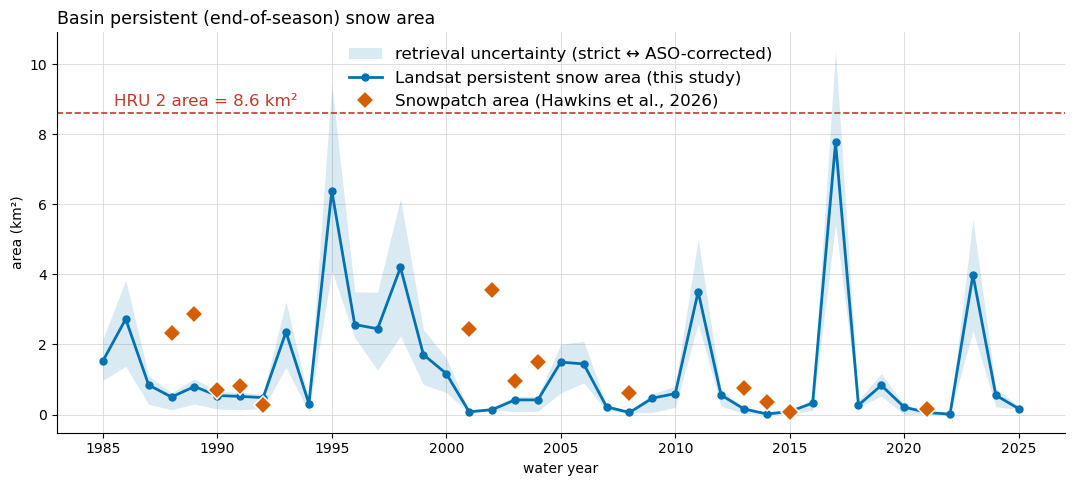

In [2]:
fig, ax = plt.subplots(figsize=(13, 5.2))

ax.fill_between(eos.index, eos.A_strict, eos.A_aso, color="#0072B2", alpha=.15, lw=0,
                label="retrieval uncertainty (strict ↔ ASO-corrected)")
ax.plot(eos.index, eos.A_shadow, color="#0072B2", lw=2.0, marker="o", ms=5,
        label="Landsat persistent snow area (this study)")

# sparse years: the minimum is taken over <=2 scenes, so these sit biased HIGH
sp = eos[eos.few_scenes]
# ax.scatter(sp.index, sp.A_shadow, s=170, facecolor="none", edgecolor="#c0392b",
#            lw=1.8, zorder=6, label="≤2 usable scenes (biased high)")
# for y, r_ in sp.iterrows():
#     ax.annotate(f"n={int(r_.n_scenes)}", (y, r_.A_shadow), fontsize=7.5,
#                 color="#c0392b", ha="center",
#                 textcoords="offset points", xytext=(0, 13))

ax.plot(pub.index, pub.combined_km2 - pub.glacier_km2, color="#D55E00", lw=0, marker="D", ms=9,
        markeredgecolor="white", markeredgewidth=1.1,
        label="Snowpatch area (Hawkins et al., 2026)")
# ax.plot(pub.index, pub.glacier_km2, color="#D55E00", lw=1.2, ls=":", alpha=.8,
#         marker="v", ms=5, label="published: glacier only (NDSI-invisible floor)")

ax.axhline(A_HRU2, color="#c0392b", lw=1.2, ls="--")
ax.annotate(f"HRU 2 area = {A_HRU2:.1f} km²", (1985.5, A_HRU2),
            textcoords="offset points", xytext=(0, 5), fontsize=12, color="#c0392b")

ax.set_xlabel("water year"); ax.set_ylabel("area (km²)")
ax.set_title("Basin persistent (end-of-season) snow area", loc="left", fontsize=12.5)
ax.legend(frameon=False, fontsize=12)
ax.grid(True, color="#d8d8d8", lw=.6); ax.set_axisbelow(True)
for s in ("top","right"): ax.spines[s].set_visible(False)
plt.show()

### 1a · How many scenes stand behind each year?

The annual value is a **minimum**, so it is only as good as the sampling. A lone
scene is not a minimum — in well-sampled years a *randomly chosen* scene sits ~4×
above the annual minimum (median; IQR 1.9–16.4×). For a *well-timed* mid-September
scene like 1992's the penalty is smaller, ~1.6× (IQR 1.2–4.2×), but still upward.

Only **1992** has a single scene; **1990** and **1991** have two. Excluding all three
changes the recession fit negligibly (r 0.833 → 0.833, slope 0.482 → 0.488 /m), so
they are safe to keep — but they should be marked, not silently averaged in.


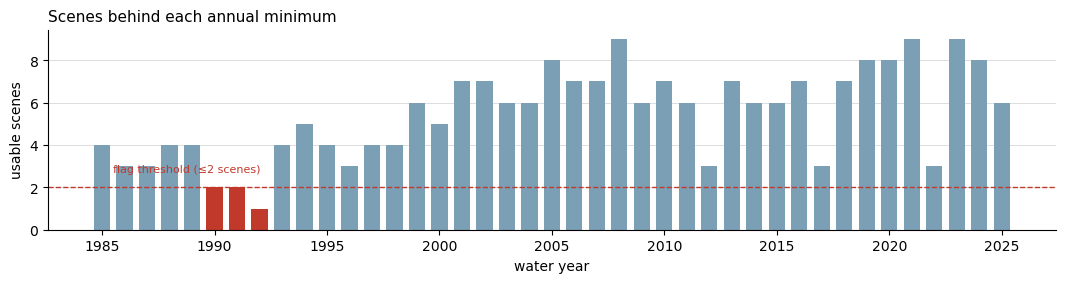

all years      n=41  r=+0.833  slope=0.482/m
excl. sparse   n=38  r=+0.833  slope=0.488/m


In [3]:
fig, ax = plt.subplots(figsize=(13, 2.6))
cols = ["#c0392b" if v else "#7b9fb5" for v in eos.few_scenes]
ax.bar(eos.index, eos.n_scenes, color=cols, width=.72)
ax.axhline(2, color="#c0392b", lw=1, ls="--")
ax.annotate("flag threshold (≤2 scenes)", (1985.5, 2.7), fontsize=8, color="#c0392b")
ax.set_ylabel("usable scenes"); ax.set_xlabel("water year")
ax.set_title("Scenes behind each annual minimum", loc="left", fontsize=11)
ax.grid(True, axis="y", color="#d8d8d8", lw=.6); ax.set_axisbelow(True)
for s_ in ("top","right"): ax.spines[s_].set_visible(False)
plt.show()

# sensitivity: does dropping the sparse years move the recession fit?
jj = eos.join(peak.rename("peak_mm"), how="inner").dropna(subset=["peak_mm"])
for lab, sub in [("all years", jj), ("excl. sparse", jj[~jj.few_scenes])]:
    x_, y_ = sub.peak_mm/1000, sub.f_shadow
    b_, a_ = np.polyfit(x_, y_, 1)
    print(f"{lab:14s} n={len(sub):2d}  r={np.corrcoef(x_,y_)[0,1]:+.3f}  slope={b_:.3f}/m")

### 1b · Direct comparison on the overlapping years

## 2 · Recession curve — does more peak SWE mean more persistent snow?

x is the **modelled** HRU-2 peak SWE from the calibrated long-term baseline
(`Tuolumne_River_baseline_wbias10_1981_2025`), validated against ASO at r = 0.944.
y is the effective fSCA of the snowpatch HRU.

The slope is the `d(fSCA)/d(SWE)` the dynamic-snowpatch scheme needs.


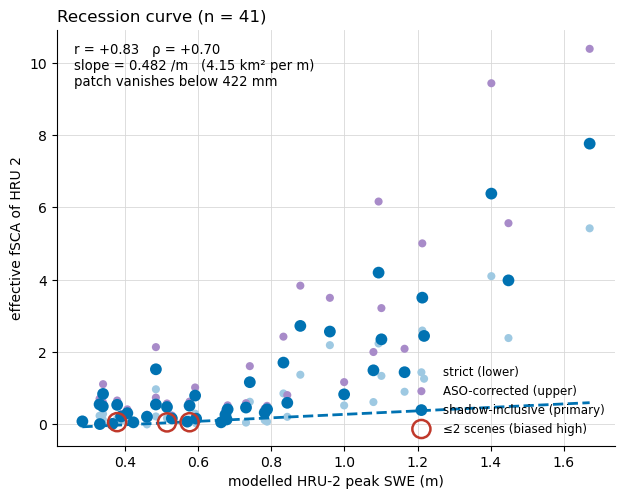

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 5.4))
j = eos.join(peak.rename("peak_mm"), how="inner").dropna(subset=["peak_mm"])
x = j.peak_mm/1000

for col, c, lab, s in [("A_strict","#9ec9e2","strict (lower)",34),
                       ("A_aso","#a88bc9","ASO-corrected (upper)",34),
                       ("A_shadow","#0072B2","shadow-inclusive (primary)",72)]:
    ax.scatter(x, j[col], s=s, color=c, lw=.9, zorder=3 if col=="f_shadow" else 2,
               edgecolor="white" if col=="f_shadow" else "none", label=lab)

sp = j[j.few_scenes]
ax.scatter(sp.peak_mm/1000, sp.f_shadow, s=170, facecolor="none",
           edgecolor="#c0392b", lw=1.8, zorder=5, label="≤2 scenes (biased high)")

b, a = np.polyfit(x, j.f_shadow, 1)
xf = np.linspace(x.min(), x.max(), 50)
ax.plot(xf, a + b*xf, color="#0072B2", lw=2, ls="--", zorder=4)
r  = np.corrcoef(x, j.f_shadow)[0,1]
rs = x.corr(j.f_shadow, method="spearman")
ax.annotate(f"r = {r:+.2f}   ρ = {rs:+.2f}\n"
            f"slope = {b:.3f} /m   ({b*A_HRU2:.2f} km² per m)\n"
            f"patch vanishes below {-a/b*1000:.0f} mm",
            (0.03,0.97), xycoords="axes fraction", va="top", fontsize=9.5)

ax.set_xlabel("modelled HRU-2 peak SWE (m)")
ax.set_ylabel("effective fSCA of HRU 2")
ax.set_title(f"Recession curve (n = {len(j)})", loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.grid(True, color="#d8d8d8", lw=.6); ax.set_axisbelow(True)
for s in ("top","right"): ax.spines[s].set_visible(False)
plt.show()

## 2b · Nonlinear recession curves

fSCA is bounded in [0,1]; a straight line is not. The linear fit predicts
**negative** cover below ~0.42 m and exceeds 1 above ~2.5 m. Nonlinear forms fit
much better (R² 0.69 → 0.83) and two of them stay inside the bounds.

| model | R² | ΔAICc | f(3 m) |
|---|---|---|---|
| power `a·S^b` | 0.832 | 0.0 | **4.56** ✗ unbounded |
| **logistic, ceiling pinned at 1** | 0.827 | **1.3** | **0.999** ✓ |
| Hill | 0.804 | 6.3 | 0.977 ✓ |
| linear | 0.694 | 24.6 | 1.24 ✗ |

**Recommended: the bounded logistic** — 1.3 AICc from the best fit, and the only
top model that cannot leave [0,1].

$$f(S) = \frac{1}{1 + e^{-4.043\,(S - 1.331)}}$$

### The physical model (panel C)

The ASO flights say the within-HRU depth distribution is lognormal with
**CV ≈ 1.01**. If end-of-season area is simply the part of that distribution
deeper than the season's ablation `E`, the curve follows with *one* free parameter:
`f(S) = P(d > E)`, `d ~ LN(mean=S, CV=1.01)`.

Applied to the **basin** response this fits worst of all — but that is a scale
error, not a failed model: CV was measured *inside HRU 2*, not basin-wide.
Applied at the scale it was measured (band 8) it **wins on AICc** (R² 0.718 with
one parameter, E = 2.30 m), and freeing CV lands on **1.24 vs ASO's measured 1.01**.

That matters for the build: the 16-bin construction is drawn from this same
distribution, so it should reproduce band-8 depletion **without further tuning**.
E = 2.30 m of effective seasonal ablation is also consistent with the 1.5–4 m/yr
seen in the earlier snowpatch runs.


,model,k,R2,AICc,dAICc,f_at_3m,params
0,Fitted logistic regression,2,0.827,-200.1,0.0,0.999,"[4.043, 1.331]"


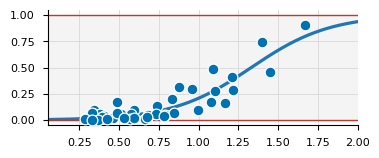

band 8, CV fixed at ASO 1.01 -> E = 2.30 m
band 8, CV free              -> E = 2.40 m, CV = 1.24  (ASO 1.01)


In [5]:
from scipy.optimize import curve_fit
from scipy.stats import norm
plt.style.use("seaborn-v0_8-paper")

def f_linear(S, a, b):    return a + b*S
def f_power(S, a, b):     return a*np.power(np.clip(S,1e-9,None), b)
def f_logistic1(S, k, S0): return 1.0/(1.0+np.exp(-k*(S-S0)))      # bounded
# def f_hill(S, S50, n):    S=np.clip(S,1e-9,None); return S**n/(S50**n+S**n)
def f_lognorm(S, E, cv):
    S=np.clip(S,1e-9,None); sig=np.sqrt(np.log(1+cv**2)); mu=np.log(S)-0.5*sig**2
    return 1.0-norm.cdf((np.log(max(E,1e-9))-mu)/sig)

j = eos.join(peak.rename("peak_mm"), how="inner").dropna(subset=["peak_mm"])
x, y = (j.peak_mm/1000).values, j.f_shadow.values

CANDIDATES = [
            # ("linear", f_linear, [0,.5], 2),
            #   ("power a·S^b", f_power, [.3,2.], 2),
              ("Fitted logistic regression", f_logistic1, [4.,1.33], 2),
            #   ("Hill", f_hill, [1.3,4.], 2),
            #   ("lognormal CV=1.01", lambda S,E: f_lognorm(S,E,1.01), [1.5], 1)
              ]

rows=[]
for nm, fn, p0, k in CANDIDATES:
    p,_ = curve_fit(fn, x, y, p0=p0, maxfev=200000)
    sse = float(((y-fn(x,*p))**2).sum()); n=len(x)
    r2  = 1-sse/float(((y-y.mean())**2).sum())
    aicc= n*np.log(sse/n)+2*k + (2*k*(k+1))/(n-k-1)
    rows.append(dict(model=nm, k=k, R2=round(r2,3), AICc=round(aicc,1),
                     f_at_3m=round(float(fn(3.0,*p)),3),
                     params=np.round(p,3), fn=fn, p=p))
tab = pd.DataFrame(rows).sort_values("AICc")
tab["dAICc"] = (tab.AICc - tab.AICc.min()).round(2)
display(tab[["model","k","R2","AICc","dAICc","f_at_3m","params"]])

fig, ax = plt.subplots(1, figsize=(4, 1.5))

lo = 0.05
hi = 2.0
ttl = "" 
xf=np.linspace(lo,hi,400)
ax.axhspan(0,1,color="#f4f4f4",zorder=0)
ax.scatter(x,y,s=60,color="#0072B2",edgecolor="white",lw=.9,zorder=5)
for _,r_ in tab.iterrows():
    best = r_.dAICc==0
    ax.plot(xf, r_.fn(xf,*r_.p), lw=2.3 if best else 1.3,
            ls="-" if best else "--", label=f"{r_.model}") #  (ΔAICc {r_.dAICc})
ax.axhline(0,color="#c0392b",lw=1); ax.axhline(1,color="#c0392b",lw=1)
ax.set_xlim(lo,hi); ax.set_ylim(-0.05,1.05)
# ax.set_xlabel("Modeled peak SWE (m)"); ax.set_ylabel("WY minimum fSCA\n[Landsat]")
ax.set_title(ttl, loc="left", fontsize=12)
ax.grid(True,color="#d8d8d8",lw=.6); ax.set_axisbelow(True)
for s_ in ("top","right"): ax.spines[s_].set_visible(False)
# ax.legend(frameon=True,)
plt.show()


# the physical model, at the scale ASO measured it
y8 = j.fsca_b8_sh.values
p8,_ = curve_fit(lambda S,E: f_lognorm(S,E,1.01), x, y8, p0=[2.], maxfev=200000)
pf,_ = curve_fit(f_lognorm, x, y8, p0=[2.,1.], maxfev=200000)
print(f"band 8, CV fixed at ASO 1.01 -> E = {p8[0]:.2f} m")
print(f"band 8, CV free              -> E = {pf[0]:.2f} m, CV = {pf[1]:.2f}  (ASO 1.01)")


## 2c · Does ASO agree with the Landsat retrieval?

**The honest limit first: ASO never flies later than August.** All 51 flights fall
in Jan–Aug (latest = 2017-08-16), so *no* ASO flight samples the end-of-season
minimum the recession curve describes. ASO therefore **cannot** be expected to land
on that curve — it should sit *above* it, by a gap that closes as day-of-year
advances. So the curve is not what this section tests.

What ASO *can* do is test the retrieval the curve is built from. Restricting to the
Jul–Oct window gives only **3** near-coincident pairs — too few to conclude from.
Expanding to the full ASO era gives **n = 38** matched pairs (flights Mar–Aug,
|lag| ≤ 6 d), and there band-8 agreement is **consistent with 1:1**:

| ASO threshold | slope (n = 38) | r | bias | p |
|---|---|---|---|---|
| **SWE > 0.01 m** | **1.01** | **+0.902** | **−0.008** | 1e-14 |
| SWE > 0.25 m | 1.89 | +0.462 | +0.438 | 3.5e-03 |
| SWE > 0.50 m | 2.79 | +0.257 | +0.594 | 0.12 |

**Landsat NDSI detects snow *presence*, so the matching ASO definition is "any snow"**
(SWE > 0.01 m) — at that threshold the two products are unbiased against each other
(slope 1.01, RMSE 0.130). The 0.25 m threshold only *looked* right on the 3-flight
late-season set, where almost nothing thin is left to disagree about; over 38 flights
it over-rejects thin snow that Landsat does see, and reads 1.9× low.

This is robust to data quality: restricting to cloud < 20%, or Landsat valid fraction
> 0.7, or |lag| ≤ 3 d all leave slope at 1.00 and bias within ±0.03. It also holds late
in the season — **Jun–Aug alone: n = 8, slope 0.80, r = +0.850, p = 0.008** — so it is
not an artefact of the spring flights dominating the fit.

**What this does and does not establish.** It supports the *retrieval*: where the two
sensors overlap in time, they track each other, including into midsummer. It does **not**
establish that the September/October minima the curve is fitted to are unbiased, because
no airborne data exist at that time of year. That gap is a property of the ASO record and
cannot be closed with these data.


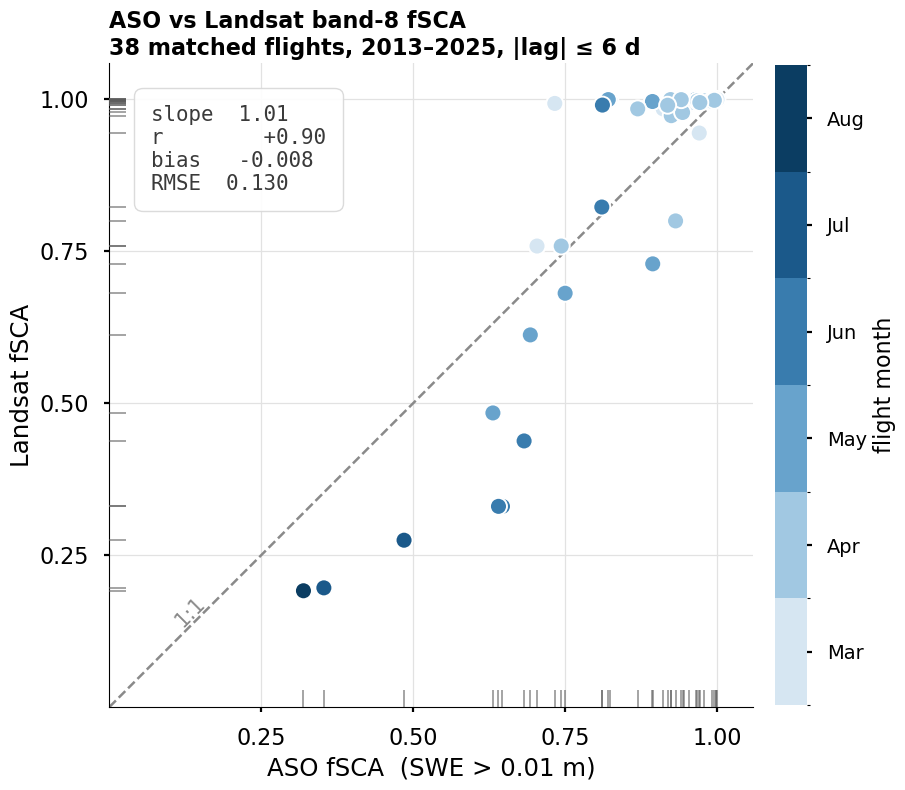

ASO flights: 51, months [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8)] (never Sep/Oct -> cannot sample the EOS minimum)
matched pairs: n = 38, |lag| <= 6 d

  band-8, ASO SWE>0.01: slope = 1.01, r = +0.902, bias = -0.008
  band-8, ASO SWE>0.25: slope = 1.89, r = +0.462, bias = +0.438
  band-8, ASO SWE>0.50: slope = 2.79, r = +0.257, bias = +0.594


In [6]:
# ---- ASO vs Landsat band-8 fSCA, all 38 matched flights ------------------------------
# NB: aso_landsat_pairs_all.csv holds only the 3 Jul-Oct matches. The Mar-Aug set
# (aso_landsat_pairs_spring.csv) has n = 38 and is what the table above reports.
from matplotlib.offsetbox import AnchoredText
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap

aso_all = pd.read_csv(DATA/"aso_all_flights.csv", parse_dates=["date"])
pairs38 = pd.read_csv(DATA/"aso_landsat_pairs_spring.csv",
                      parse_dates=["aso_date", "ls_date"])

# Landsat NDSI detects snow PRESENCE, so the matching ASO definition is "any snow"
# (SWE > 0.01 m) -- not the 0.25 m threshold the 3-flight set appeared to endorse.
x, y = pairs38.aso_b8_t001.to_numpy(float), pairs38.ls_b8.to_numpy(float)
k0   = (x*y).sum()/(x*x).sum()                 # slope through the origin
r    = np.corrcoef(x, y)[0, 1]
bias = (y - x).mean()
rmse = float(np.sqrt(((y - x)**2).mean()))

# sequential single hue, light (Mar) -> dark (Aug): season is a magnitude, not an identity
CMAP = LinearSegmentedColormap.from_list(
    "season", ["#d6e6f2", "#94c1de", "#4a8fc0", "#1f6094", "#0b3d62"])
NORM = BoundaryNorm(np.arange(2.5, 9.5, 1.0), CMAP.N)

with plt.style.context("seaborn-v0_8-poster"):
    fig, ax = plt.subplots(figsize=(9.0, 8.0))
    lim = (0.0, 1.06)

    ax.plot(lim, lim, ls="--", lw=1.8, color="#8a8a8a", zorder=2)
    sc = ax.scatter(x, y, c=pairs38.month, cmap=CMAP, norm=NORM,
                    s=150, edgecolor="white", lw=1.4, zorder=4)

    # marginal rugs: where the flights actually concentrate
    rug = 0.026*(lim[1] - lim[0])
    ax.vlines(x, lim[0], lim[0] + rug, color="#5c5c5c", lw=1.3, alpha=0.6, zorder=3)
    ax.hlines(y, lim[0], lim[0] + rug, color="#5c5c5c", lw=1.3, alpha=0.6, zorder=3)

    # upper-left is the empty half; borderpad insets the box clear of the y-rug
    at = AnchoredText(f"slope  {k0:.2f}\nr        {r:+.2f}\nbias   {bias:+.3f}\nRMSE  {rmse:.3f}",
                      loc="upper left", frameon=True, borderpad=1.6,
                      prop=dict(fontsize=15, family="DejaVu Sans Mono", color="#3a3a3a"))
    at.patch.set(boxstyle="round,pad=0.4", fc="white", ec="#d8d8d8", lw=1.0, alpha=0.92)
    at.set_zorder(6)
    ax.add_artist(at)
    ax.annotate("1:1", (0.145, 0.145), fontsize=15, color="#8a8a8a",
                rotation=45, rotation_mode="anchor", va="bottom", ha="center")

    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_aspect("equal")
    ax.set_xticks([0.25, 0.50, 0.75, 1.00])
    ax.set_yticks([0.25, 0.50, 0.75, 1.00])
    ax.set_xlabel("ASO fSCA  (SWE > 0.01 m)")
    ax.set_ylabel("Landsat fSCA")
    ax.grid(color="#e2e2e2", lw=0.9); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)

    cb = fig.colorbar(sc, ax=ax, ticks=range(3, 9), pad=0.03, fraction=0.045)
    cb.set_label("flight month", fontsize=16)
    cb.ax.set_yticklabels(["Mar", "Apr", "May", "Jun", "Jul", "Aug"], fontsize=14)
    cb.outline.set_visible(False)

    ax.set_title(f"ASO vs Landsat band-8 fSCA\n{len(pairs38)} matched flights, "
                 f"{pairs38.aso_date.min():%Y}–{pairs38.aso_date.max():%Y}, |lag| ≤ 6 d",
                 loc="left", fontsize=16, fontweight="bold")
    fig.tight_layout()
    plt.show()

print(f"ASO flights: {len(aso_all)}, months {sorted(aso_all.date.dt.month.unique())} "
      "(never Sep/Oct -> cannot sample the EOS minimum)")
print(f"matched pairs: n = {len(pairs38)}, |lag| <= {pairs38.lag.abs().max()} d\n")
for c, lab in [("aso_b8_t001", "SWE>0.01"), ("aso_b8_t025", "SWE>0.25"),
               ("aso_b8_t05",  "SWE>0.50")]:
    xi = pairs38[c].to_numpy(float)
    print(f"  band-8, ASO {lab}: slope = {(xi*y).sum()/(xi*xi).sum():.2f}, "
          f"r = {np.corrcoef(xi, y)[0,1]:+.3f}, bias = {(y-xi).mean():+.3f}")


## 3 · Where the snow is, and the scene-level data

`scene` holds every Landsat scene, so you can change the window, swap the
annual-minimum statistic, or look at within-season depletion.
Columns per elevation band `b`: `fsca_b{b}` / `fsca_b{b}_sh` (strict / shadow-inclusive),
`nv_b{b}` (valid px), `ns_b{b}` (snow px).

Band 8 = 3682 m (13.0 km²), 7 = 3383 m (97.1 km²), 6 = 3059 m (270.6 km²),
5 = 2746 m (256.3 km²), 4 = 2414 m, 3 = 2060 m, 2 = 1607 m.


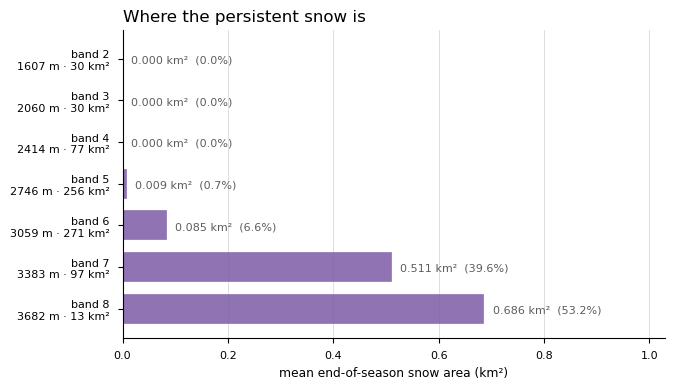

,elev_m,area_km2,snow_km2,pct
band,,,,
8,3682,13.0,0.686343,53.2
7,3383,97.1,0.510784,39.6
6,3059,270.6,0.084686,6.6
5,2746,256.3,0.008637,0.7
4,2414,76.9,0.000036,0.0
3,2060,30.2,0.000329,0.0
2,1607,30.4,0.000000,0.0


In [7]:
BAND_AREA = {8:13.0, 7:97.1, 6:270.6, 5:256.3, 4:76.9, 3:30.2, 2:30.4}
BAND_ELEV = {8:3682, 7:3383, 6:3059, 5:2746, 4:2414, 3:2060, 2:1607}
bands = [8,7,6,5,4,3,2]

share = pd.DataFrame({
    "elev_m":   [BAND_ELEV[b] for b in bands],
    "area_km2": [BAND_AREA[b] for b in bands],
    "snow_km2": [eos[f"fsca_b{b}_sh"].mean()*BAND_AREA[b] for b in bands],
}, index=pd.Index(bands, name="band"))
share["pct"] = (100*share.snow_km2/share.snow_km2.sum()).round(1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(range(len(bands)), share.snow_km2, color="#7b5aa6", alpha=.85,
        edgecolor="white", height=.72)
ax.set_yticks(range(len(bands)))
ax.set_yticklabels([f"band {b}\n{BAND_ELEV[b]} m · {BAND_AREA[b]:.0f} km²" for b in bands],
                   fontsize=8)
for i, (v, p) in enumerate(zip(share.snow_km2, share.pct)):
    ax.annotate(f"{v:.3f} km²  ({p}%)", (v, i), xytext=(6,-3),
                textcoords="offset points", fontsize=8, color="#5c5c5c")
ax.set_xlim(0, share.snow_km2.max()*1.5)
ax.set_xlabel("mean end-of-season snow area (km²)")
ax.set_title("Where the persistent snow is", loc="left", fontsize=12)
ax.grid(True, axis="x", color="#d8d8d8", lw=.6); ax.set_axisbelow(True)
for s in ("top","right"): ax.spines[s].set_visible(False)
plt.show()
share

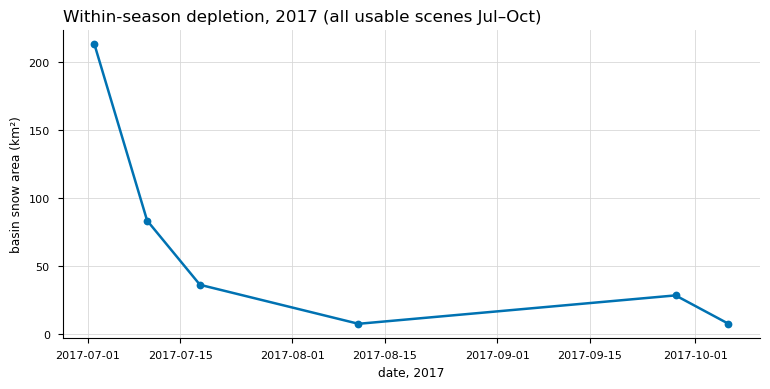

In [8]:
# within-season depletion for a chosen year -- the scene table makes this easy
YEAR = 2017
s = scene[(scene.status=="ok") & (scene.date.dt.year==YEAR)].sort_values("date")
area = sum(s[f"fsca_b{b}_sh"].fillna(0)*BAND_AREA[b] for b in bands)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(s.date, area, marker="o", color="#0072B2", lw=1.8)
ax.set_ylabel("basin snow area (km²)"); ax.set_xlabel(f"date, {YEAR}")
ax.set_title(f"Within-season depletion, {YEAR} (all usable scenes Jul–Oct)",
             loc="left", fontsize=12)
ax.grid(True, color="#d8d8d8", lw=.6); ax.set_axisbelow(True)
for sp in ("top","right"): ax.spines[sp].set_visible(False)
plt.show()

## 4 · Did the binned model actually reproduce the fSCA–SWE curve?

The bins were sized to make modelled fSCA follow the observed depletion curve. This checks
whether it worked, against the best sweep member (`m090_q089`) over the full 1985–2025 record.


## Files in `/scratch/dlhogan/ess-project-data/geospatial-data/snowpatch_fsca`

| file | what |
|---|---|
| `eos_final.csv` | the annual record — 3 tiers, per-band fSCA, the scene chosen each year, and `n_scenes` |
| `scenes_by_band3.csv` | every Landsat scene (368), both maskings, per-band valid/snow pixel counts |
| `published_glacier_snowpatch_area.csv` | the published inventory (domain unconfirmed) |
| `model_hru2_peak_swe.csv` | modelled HRU-2 peak SWE by water year, 1982–2025 |
| `aso_hru2_stats.csv` | ASO 50 m SWE stats inside HRU 2, all 51 flights |
| `aso_band_pairs.csv`, `aso_band_area.csv` | ASO vs Landsat matched pairs, by elevation band |
| `mask_variants.csv` | the 5-way QA-masking test against ASO |
| `bin_profile_norm.txt` | 16-bin normalised depth profile from 22 peak-season ASO flights |

### Caveats worth keeping in view
- **`n_scenes` matters.** The annual value is a minimum over the window, so years with
  ≤2 usable scenes (1990, 1991, 1992) are biased high and are ringed in red on both
  plots. Dropping them does not move the recession fit.
- The **terrain-shadow decision is the dominant uncertainty**, not sensor bias: CFMask
  flags 20–28% of the high north-facing terrain as "cloud shadow" even on scenes with
  0.0% cloud, and those pixels are snowier than the ones it keeps.
- ~2–3% of Aug–Oct scenes return fSCA > 0.89. Most are probably **real early-October
  snowfall**. The annual minimum ignores them — so never use per-scene values or annual
  means/maxima, only the minimum.
- The ASO factor is a **definition mismatch**, not a bias: at bands 5–6 ASO/Landsat is
  30–42× purely because ASO counts SWE > 10 mm that NDSI cannot resolve. Only the
  band 7–8 factors are meaningful, and there the two agree within ~20%.


In [9]:
# ---- data: best snowpatch member vs the Landsat record -------------------------------
import glob, xarray as xr

RUN = Path("/scratch/dlhogan/ess-project-data/domain_Tuolumne_River_distributed_elevAspect"
           "/simulations/snowpatch_anchor_20260812/anchor_m080")
SWE_TH = 0.05          # m; a bin counts as snow-covered above this (kills the autumn veneer)
LOGIT  = (4.043, 1.331)   # the design curve f(S) = 1/(1+exp(-k(S-S0))) fitted to Landsat, R2=0.83

_bins = pd.read_csv(RUN/"bin_spec.csv")
_w    = _bins.set_index("bin").area_frac                       # sums to 1 over HRU 2
_ds   = xr.open_dataset(sorted(glob.glob(str(RUN/"output/*.nc")))[0])
_hid  = _ds.hruId.values.ravel()
_t    = pd.DatetimeIndex(_ds.time.values)

# per-bin SWE in metres, one column per bin
_swe = pd.DataFrame(
    {int(r.bin): np.asarray(_ds["scalarSWE"].isel(
        hru=int(np.where(_hid == r.hruId)[0][0])).values).ravel() / 1000.0
     for r in _bins.itertuples()}, index=_t)

# modelled fSCA = area fraction of bins still holding snow on 30 Sep
_sep30 = (_t.month == 9) & (_t.day == 30)
mod_fsca = pd.Series({int(y): float(_w.values[_swe[_sep30 & (_t.year == y)].iloc[-1].values > SWE_TH].sum())
                      for y in sorted(set(_t[_sep30].year))})

# area-weighted peak SWE over HRU 2, by water year -- the x axis of the depletion curve
_wy = _t.year + (_t.month >= 10)
mod_swe = pd.Series({int(y): float((_swe[_wy == y].max() * _w).sum())
                     for y in sorted(set(_wy)) if (_wy == y).sum() > 300})

# The design curve's x is peak SWE from the ORIGINAL single-HRU-2 run, not this one.
# The binned run carries multi-metre perennial carryover, so its area-weighted peak SWE
# runs ~2x larger (mean 1.55 m vs 0.74 m) -- plotting the curve against it shifts every
# Landsat point off the fit. Keep both; use `swe_design` for the depletion curve.
swe_design = pd.read_csv(DATA/"model_hru2_peak_swe.csv", index_col="year")["peak_swe_mm"]/1000.0

snowpatch_cmp = pd.DataFrame({
    "swe_design": swe_design,       # original HRU-2 run, m -- the curve was fitted on this
    "swe_binned": mod_swe,          # this run, area-weighted, m
    "fsca_mod":   mod_fsca,         # model, 0-1
    "fsca_obs":   eos.f_shadow,     # Landsat primary tier
    "area_mod":   mod_fsca * A_HRU2,
    "area_obs":   eos.A_shadow,     # km2
}).dropna(subset=["fsca_mod", "fsca_obs"])

_n0 = int((snowpatch_cmp.fsca_mod == 0).sum())
print(f"n = {len(snowpatch_cmp)} years, {snowpatch_cmp.index.min()}-{snowpatch_cmp.index.max()}")
print(f"mean fSCA   model {snowpatch_cmp.fsca_mod.mean():.3f}  obs {snowpatch_cmp.fsca_obs.mean():.3f}"
      f"   ratio {snowpatch_cmp.fsca_mod.mean()/snowpatch_cmp.fsca_obs.mean():.2f}")
print(f"correlation r = {snowpatch_cmp.fsca_mod.corr(snowpatch_cmp.fsca_obs):.3f}")
print(f"model hits exactly zero in {_n0} of {len(snowpatch_cmp)} years; "
      f"observed minimum is {snowpatch_cmp.fsca_obs.min():.3f} (never zero)")

# sanity check: the published logistic should reproduce the Landsat points on swe_design
_v = snowpatch_cmp.dropna(subset=["swe_design"])
_p = 1/(1 + np.exp(-LOGIT[0]*(_v.swe_design - LOGIT[1])))
_r2 = 1 - ((_v.fsca_obs - _p)**2).sum()/((_v.fsca_obs - _v.fsca_obs.mean())**2).sum()
print(f"design curve vs Landsat on swe_design: R2 = {_r2:.3f}  (published fit: 0.827)")
print(f"peak SWE  design-run {snowpatch_cmp.swe_design.mean():.2f} m   "
      f"binned-run {snowpatch_cmp.swe_binned.mean():.2f} m")


n = 41 years, 1985-2025
mean fSCA   model 0.150  obs 0.150   ratio 1.00
correlation r = 0.883
model hits exactly zero in 0 of 41 years; observed minimum is 0.001 (never zero)
design curve vs Landsat on swe_design: R2 = 0.827  (published fit: 0.827)
peak SWE  design-run 0.73 m   binned-run 1.21 m


In [10]:
%matplotlib inline

  Landsat          WY1992-2025 n=34  -6.97%/yr  rho=-0.35 p=0.045
  SUMMA-snowpatch  WY1992-2025 n=34  -8.30%/yr  rho=-0.39 p=0.023


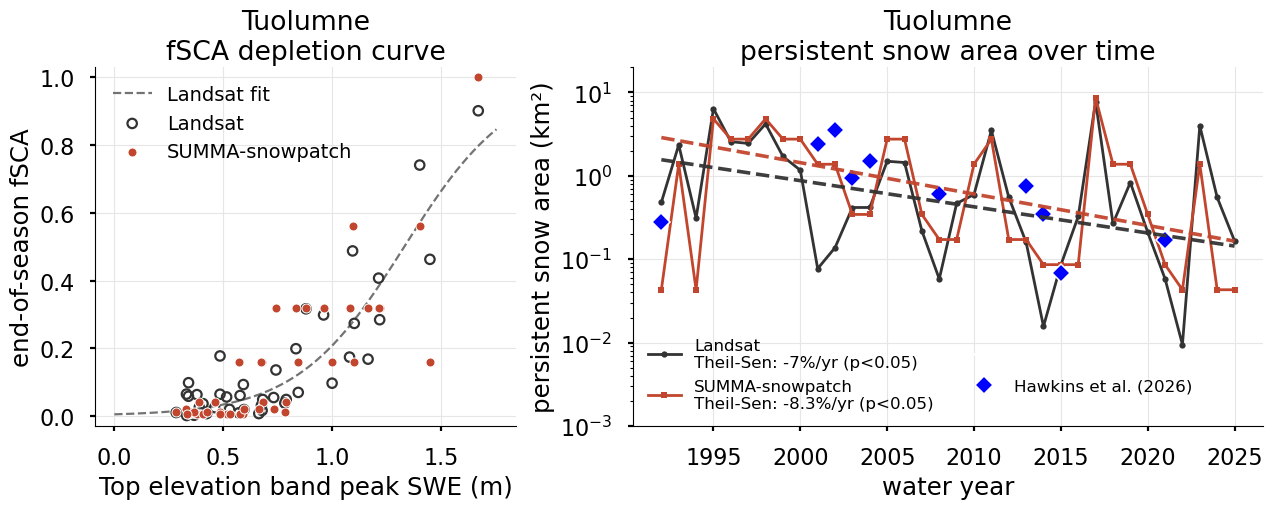

In [11]:
# ---- plot: depletion curve, and area through time ------------------------------------
plt.style.use("seaborn-v0_8-poster")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw=dict(width_ratios=[1, 1.5]))
OBS_C, MOD_C = "#333333", "#c2452d",

# (A) fSCA vs peak SWE, with the curve the bins were designed to reproduce
ax = axes[0]
_v = snowpatch_cmp.dropna(subset=["swe_design"])
_s = np.linspace(0, _v.swe_design.max()*1.05, 200)
ax.plot(_s, 1/(1 + np.exp(-LOGIT[0]*(_s - LOGIT[1]))), color="0.45", lw=1.6, ls="--",
        zorder=2, label="Landsat fit")
ax.scatter(_v.swe_design, _v.fsca_obs, s=46, facecolor="none",
           edgecolor=OBS_C, lw=1.6, zorder=3, label="Landsat")
ax.scatter(_v.swe_design, _v.fsca_mod, s=42, color=MOD_C,
           edgecolor="white", lw=0.7, zorder=4, label="SUMMA-snowpatch")
ax.set_xlabel("Top elevation band peak SWE (m)")
ax.set_ylabel("end-of-season fSCA")
ax.set_ylim(-0.03, 1.03)
ax.legend(frameon=False, fontsize=14, loc="upper left")
ax.set_title("Tuolumne\nfSCA depletion curve", loc="center",)

# (B) persistent snow area through time
ax = axes[1]
ax.plot(snowpatch_cmp.loc[1992:].index, snowpatch_cmp.loc[1992:].area_obs, color=OBS_C, lw=2.0, marker="o",
        ms=4.5, label="Landsat\nTheil-Sen: -7%/yr (p<0.05)")
ax.plot(snowpatch_cmp.loc[1992:].index, snowpatch_cmp.loc[1992:].area_mod, color=MOD_C, lw=2.0, marker="s",
        ms=4.5, label="SUMMA-snowpatch\nTheil-Sen: -8.3%/yr (p<0.05)")
ax.plot([], [], color='white', lw=2.0, marker="o", ms=4.5, label="\n")
ax.plot(pub.loc[1992:].index, pub.loc[1992:].combined_km2 - pub.loc[1992:].glacier_km2, color="blue", lw=0, marker="D", ms=9,
        markeredgecolor="white", markeredgewidth=1.1,
        label="Hawkins et al. (2026)")

# Theil-Sen slope over the PLOTTED window, fitted in log space so the trend is
# multiplicative -- on a log axis a linear fit would be a curve, and could dip below zero.
# Significance is Spearman's rank correlation against water year, which is the
# non-parametric partner to a Theil-Sen slope.
from scipy.stats import theilslopes as _theil, spearmanr as _spear

_sen = []
for _col, _c, _nm in (("area_obs", OBS_C, "Landsat"),
                      ("area_mod", MOD_C, "SUMMA-snowpatch")):
    _d = snowpatch_cmp.loc[1992:, _col].dropna()
    _d = _d[_d > 0]                                    # log space needs strictly positive
    _x = _d.index.values.astype(float)
    _sl, _ic, _, _ = _theil(np.log(_d.values), _x)
    _rho, _p = _spear(_x, _d.values)
    _e = _x[[0, -1]]
    ax.plot(_e, np.exp(_sl*_e + _ic), color=_c, lw=2.6, ls="--", alpha=0.95, zorder=6)
    _mark = "**" if _p < 0.05 else "+" if _p < 0.10 else ""
    _sen.append(f"{_nm}: {100*(np.exp(_sl)-1):+.1f}%/yr{_mark}")
    print(f"  {_nm:16s} WY{int(_x[0])}-{int(_x[-1])} n={len(_d):2d}  "
          f"{100*(np.exp(_sl)-1):+.2f}%/yr  rho={_rho:+.2f} p={_p:.3f}")

# ax.annotate("Theil-Sen:  " + "   ".join(_sen), xy=(0.985, 0.965),
#             xycoords="axes fraction", ha="right", va="top", fontsize=12.5,
#             bbox=dict(fc="white", ec="0.8", alpha=0.9, pad=3.0))


ax.set_xlabel("water year")
ax.set_ylabel("persistent snow area (km²)")
ax.set_title("Tuolumne\npersistent snow area over time", loc="center",)

# Log y, because the whole point is that the store never empties -- on a linear axis
# every value below ~0.2 km² collapses onto the baseline and "small" is indistinguishable
# from "zero". The anchor bin sets a hard floor the model cannot go below. Landsat never
# reads zero either, but its minimum (0.0095 km², 2022) is ~4.5x lower than that floor,
# so the model's persistent patch is the more conservative claim of the two.
_floor = float(_bins.area_km2.iloc[0])
ax.set_yscale("log")
ax.set_ylim(6e-3, 14)
# ax.axhline(_floor, color=MOD_C, lw=1.1, ls=":", zorder=1)
# both labels sit in the empty band below the floor line, left of the Landsat dips
# ax.annotate(f"SUMMA-snowpatch min={_floor:.3f} km²", (1985.4, _floor*0.80),
#             fontsize=11.5, color=MOD_C, va="top", ha="left")
_ymin = snowpatch_cmp.area_obs.min()
# ax.annotate(f"Landsat min={_ymin:.4f}", (int(snowpatch_cmp.area_obs.idxmin()), _ymin),
#             xytext=(-10, 2), textcoords="offset points",
#             fontsize=11.5, color=OBS_C, va="bottom", ha="right")

ax.legend(ncol=2, frameon=False, fontsize=12, loc="lower left")
ax.set_ylim(1e-3, 20)
# ax.set_title("(B)", loc="left", fontweight="bold")

for ax in axes:
    ax.grid(color="0.9", lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()



## 5 · Snow pillow vs the HRU containing it

Point-scale check on the snow model, independent of everything above. Each pillow is
compared against the **single HRU it falls inside** — not a basin mean — using the
calibrated full-record baselines (`East_River_baseline_1981_2025`,
`Tuolumne_River_baseline_wbias10_1981_2025`).

| site | elev | HRU | HRU elev | Δ | station-years |
|---|---|---|---|---|---|
| Butte (NRCS) | 3106 m | 13 | 3016 m | −90 m | 42 |
| Dana Meadows (CDEC) | 2975 m | 10 | 3057 m | +82 m | 22 |
| Slide Canyon (CDEC) | 2804 m | 17 | 2747 m | −57 m | 21 |
| Tuolumne Meadows (CDEC) | 2591 m | 13 | 2730 m | +139 m | 27 |
| ~~Gaylor Pit~~ | 2804 m | — | — | — | **no SWE column** (depth only, from 2019) |

**One value per basin-year, on a shared year set.** Site-years are averaged within a
basin and then restricted to the years *both* basins have, so the two rows of every
panel are built from identical water years — **37 of them, 1984–2024**.

### Three data problems that had to be fixed first

**1 · Hard sensor faults.** Butte is clean, but the CDEC pillows record a **200 m** SWE
spike at Tuolumne Meadows in April 2001, a **762 m** spike at Slide Canyon, and 850–2600
negative readings each. Unfiltered, Tuolumne's peak-SWE RMSE comes out at **20 487 mm**.
Whole water years failing a physical check (> 2.5 m, |Δ| > 200 mm/d, any reading
< −50 mm, < 150 valid days in Dec 1–Jul 15, or a peak on the first/last reading) are
dropped rather than repaired, since every metric is per-year anyway.

**2 · Multiple melt-outs.** 18 observed seasons melt out, re-accumulate and melt again.
Taking the *first* drop below threshold gives a spuriously early date, so melt-out is
defined as the day after the **last** reading above threshold — unique by construction,
always after the peak, and required to fall after **1 March**. A melt date is only
accepted with ≥ 14 days of below-threshold record after it, so a season that simply
runs out of data is not counted as melted.

**3 · The melt threshold is not innocent.** Butte sits on a perfect zero floor, but the
CDEC pillows carry an end-of-summer offset of up to 48 mm (Dana p90 = 17 mm). At a
10 mm threshold that drift reads as a pack that never melts — it cost 26 of 40 Dana
melt-out dates and **flipped the sign** of Tuolumne's melt-out error. On a fixed
28-year sample:

| threshold | East ME | Tuolumne ME |
|---|---|---|
| 10 mm | +6.6 d | **−14.0 d** ← contaminated by drift |
| **25.4 mm (1 in)** | +11.5 d | **+3.6 d** |
| 40 mm | +10.1 d | +5.0 d |

25.4 mm and 40 mm agree; the conclusion is stable once the threshold clears the drift
floor. Peak SWE RMSE and peak-timing bias do not depend on it at all. **1 inch is used
here.**

Regenerate with `ess-project/utils/snotel_metrics.py`.


In [12]:
# ---- data: snow pillow vs the HRU containing it --------------------------------------
# Built by ess-project/utils/snotel_metrics.py (reads both baseline runs + shapefiles).
#   snotel_hru_swe_metrics.csv -- every station-year that passes QA, ALL sites
#   snotel_hru_swe_annual.csv  -- one chosen site per basin, scored against BOTH the
#                                 containing HRU and the area-weighted basin mean
#                                 (`source` column), on the shared year set
# Peak SWE error is a percentage of the record's own mean observed peak (a 100 mm miss
# means something different at Butte, mean 400 mm, and Slide Canyon, 1023 mm). The IQR
# enters only as the span of the plotted line, not as the normaliser. Timing metrics stay
# in days: a day-of-water-year has an arbitrary 1 Oct origin, so normalising it is
# misleading. Duration (peak->melt-out) separates a melt-RATE error from a pure shift.
snotel_sy = pd.read_csv(DATA/"snotel_hru_swe_metrics.csv")
snotel    = pd.read_csv(DATA/"snotel_hru_swe_annual.csv")
sites     = pd.read_csv(DATA/"snotel_hru_sites.csv")

SN_BASINS = ["East", "Tuolumne"]
SN_COLOR  = {"East": "#0072B2", "Tuolumne": "#D55E00"}     # matches the MRC facet figure
SN_LO, SN_HI = 25, 75                                      # interquartile range

SN_PANELS = [
    ("nd_peak", "Peak SWE error", "% of mean observed peak",
     lambda v: f"nRMSE {100*np.sqrt((v**2).mean()):.1f}%",
     lambda x, _: f"{100*x:g}"),
    ("d_dur",   "Melt duration error  (peak → melt-out)", "days",
     lambda v: f"ME {v.mean():+.1f} d", None),
    ("d_tmelt", "Melt-out date error", "days",
     lambda v: f"ME {v.mean():+.1f} d", None),
]
# filter to just 2015-2024 to match the evaluation period 
snotel = snotel[(snotel.wy >= 2000) & (snotel.wy <= 2025)]
snotel_sy = snotel_sy[(snotel_sy.wy >= 2000) & (snotel_sy.wy <= 2025)]

# Per-site skill over every QA-passing station-year. NB: the site used is set explicitly
# in snotel_metrics.py, NOT auto-ranked -- ranking by a spread-normalised error rewards
# whichever site is most variable (Slide Canyon has the largest observed IQR, 677 mm vs
# Butte's 182, so it wins on RMSE/IQR despite the worst bias of the three).
_st = {}
for s, g in snotel_sy[snotel_sy.source == "hru"].groupby("site"):
    _st[s] = dict(basin=g.basin.iloc[0], n=len(g),
                  nRMSE_pct=100*np.sqrt((g.nd_peak**2).mean()),
                  bias_pct=100*g.nd_peak.mean(),
                  RMSE_over_IQR=np.sqrt((g.niqr_peak**2).mean()),
                  melt_ME_d=g.d_tmelt.mean(), dur_ME_d=g.d_dur.mean())
print("--- per-site skill (all QA-passing station-years) ---")
display(pd.DataFrame(_st).T.round(2))
print(f"site used per basin: { {b: g.site.iloc[0] for b, g in snotel.groupby('basin')} }")
print(f"{snotel.wy.nunique()} shared water years "
      f"({int(snotel.wy.min())}-{int(snotel.wy.max())}), one value per basin-year")
print(f"observed seasons with >1 melt-out episode: "
      f"{int((snotel_sy.loc[snotel_sy.source == 'hru', 'obs_episodes'] > 1).sum())} "
      "(resolved to the FINAL melt-out)\n")
for (b, src), g in snotel.groupby(["basin", "source"]):
    print(f"{b:9s} [{src:5s}] n={len(g):2d} yr   nRMSE {100*np.sqrt((g.nd_peak**2).mean()):5.1f}%   "
          f"peak RMSE {np.sqrt((g.d_peak**2).mean()):6.1f} mm ({100*g.nd_peak.mean():+5.1f}% bias)")
    print(f"{'':9s} melt duration  obs {g.dur_obs.mean():5.1f} d  model {g.dur_mod.mean():5.1f} d  "
          f"error {g.d_dur.mean():+5.1f} d   |   melt-out ME {g.d_tmelt.mean():+5.1f} d")


--- per-site skill (all QA-passing station-years) ---


,basin,n,nRMSE_pct,bias_pct,RMSE_over_IQR,melt_ME_d,dur_ME_d
Butte,East,26,17.942533,-16.671268,0.382116,15.0,-0.692308
Dana Meadows,Tuolumne,13,35.331745,-4.576042,0.731798,-44.75,-15.666667
Slide Canyon,Tuolumne,10,30.339306,-28.213943,0.458175,15.4,16.3
Tuolumne Meadows,Tuolumne,15,38.345787,32.164472,0.644267,28.6,19.933333


site used per basin: {'East': 'Butte', 'Tuolumne': 'Tuolumne Meadows'}
15 shared water years (2000-2024), one value per basin-year
observed seasons with >1 melt-out episode: 12 (resolved to the FINAL melt-out)

East      [basin] n=15 yr   nRMSE  13.8%   peak RMSE   55.4 mm ( +9.4% bias)
          melt duration  obs  42.3 d  model  79.5 d  error +37.3 d   |   melt-out ME +35.2 d
East      [hru  ] n=15 yr   nRMSE  17.2%   peak RMSE   68.8 mm (-15.9% bias)
          melt duration  obs  42.3 d  model  41.7 d  error  -0.5 d   |   melt-out ME +17.3 d
Tuolumne  [basin] n=15 yr   nRMSE  32.0%   peak RMSE  169.0 mm (+25.9% bias)
          melt duration  obs  55.9 d  model  97.3 d  error +41.4 d   |   melt-out ME +44.8 d
Tuolumne  [hru  ] n=15 yr   nRMSE  38.3%   peak RMSE  202.5 mm (+32.2% bias)
          melt duration  obs  55.9 d  model  75.8 d  error +19.9 d   |   melt-out ME +28.6 d


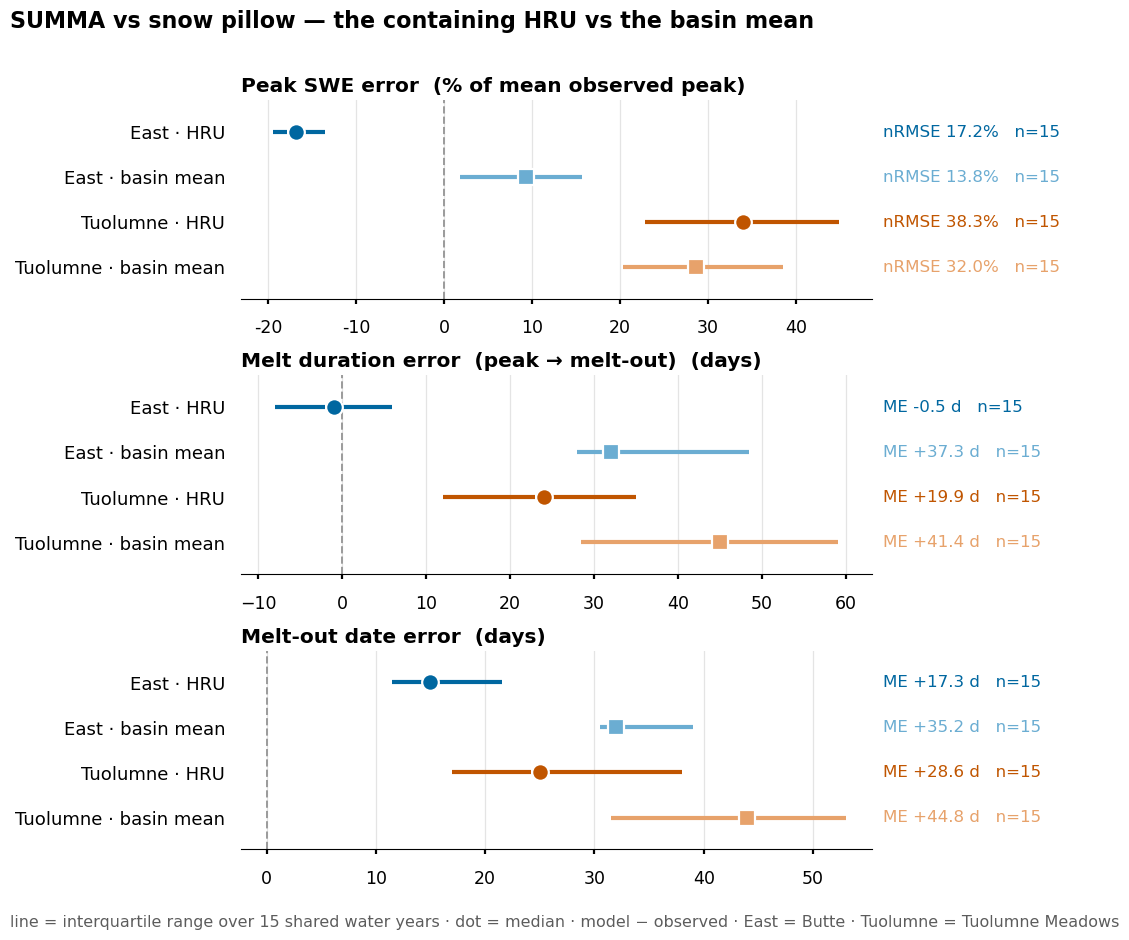

In [13]:
# ---- plot: simplified box plot (line = IQR, dot = median, gap either side) -----------
# hue = basin identity, lightness + marker = HRU vs basin mean, so either channel alone
# identifies the row (survives greyscale and CVD)
import matplotlib.colors as _mc

def sn_shade(hex_color, amount):
    r, g, b = _mc.to_rgb(hex_color)
    if amount >= 0:
        return tuple(c + (1.0 - c)*amount for c in (r, g, b))
    return tuple(c*(1.0 + amount) for c in (r, g, b))

SN_SRC  = [("hru", "HRU", -0.10, "o"), ("basin", "basin mean", 0.42, "s")]
SN_ROWS = [(b, s, lab, sh, mk) for b in SN_BASINS for s, lab, sh, mk in SN_SRC]

with plt.style.context("seaborn-v0_8-poster"):
    fig, axes = plt.subplots(3, 1, figsize=(12.5, 9.4))

    for ax, (col, name, unit, agg, fmt) in zip(axes, SN_PANELS):
        vals = {(b, s): snotel.loc[(snotel.basin == b) & (snotel.source == s), col].dropna()
                for b, s, *_ in SN_ROWS}
        allv = pd.concat(vals.values())
        pad  = 0.10*(allv.quantile(SN_HI/100) - allv.quantile(SN_LO/100))
        xlo  = min(v.quantile(SN_LO/100) for v in vals.values()) - pad
        xhi  = max(v.quantile(SN_HI/100) for v in vals.values()) + pad
        xlo, xhi = min(xlo, -pad), max(xhi, pad)      # keep the zero line on screen
        gap  = 0.014*(xhi - xlo)

        ax.axvline(0, ls="--", lw=1.4, color="#9a9a9a", zorder=1)
        for i, (b, s, lab, sh, mk) in enumerate(SN_ROWS):
            v = vals[(b, s)]
            c = sn_shade(SN_COLOR[b], sh)
            lo, med, hi = v.quantile(SN_LO/100), v.median(), v.quantile(SN_HI/100)
            y = len(SN_ROWS) - 1 - i                   # East on top
            ax.plot([lo, med - gap], [y, y], lw=3.0, color=c, solid_capstyle="butt", zorder=3)
            ax.plot([med + gap, hi], [y, y], lw=3.0, color=c, solid_capstyle="butt", zorder=3)
            ax.plot([med], [y], mk, ms=12, color=c, markeredgecolor="white",
                    markeredgewidth=1.6, zorder=4)
            ax.annotate(f"{agg(v)}   n={len(v)}", (1.0, y), xycoords=("axes fraction", "data"),
                        xytext=(8, 0), textcoords="offset points",
                        va="center", ha="left", fontsize=12, color=c)

        ax.set_yticks(range(len(SN_ROWS)-1, -1, -1))
        ax.set_yticklabels([f"{b} · {lab}" for b, s, lab, sh, mk in SN_ROWS], fontsize=13)
        ax.set_ylim(-0.7, len(SN_ROWS)-0.3); ax.set_xlim(xlo, xhi)
        ax.set_title(f"{name}  ({unit})", loc="left", fontsize=14.5, fontweight="bold")
        if fmt is not None:
            ax.xaxis.set_major_formatter(fmt)
        ax.grid(axis="x", color="#e4e4e4", lw=0.9); ax.set_axisbelow(True)
        ax.tick_params(axis="x", labelsize=12.5)
        ax.tick_params(axis="y", length=0)
        for sp in ("top", "right", "left"):
            ax.spines[sp].set_visible(False)

    fig.suptitle("SUMMA vs snow pillow — the containing HRU vs the basin mean",
                 x=0.008, ha="left", fontsize=16, fontweight="bold")
    fig.text(0.008, 0.004,
             f"line = interquartile range over {snotel.wy.nunique()} shared water years · "
             f"dot = median · model − observed · "
             + " · ".join(f"{b} = {snotel.loc[snotel.basin == b, 'site'].iloc[0]}"
                          for b in SN_BASINS),
             ha="left", fontsize=11.5, color="#5c5c5c")
    fig.tight_layout(rect=(0, 0.03, 0.86, 0.965))
    plt.show()


In [14]:
# ---- modelled basin-mean peak SWE per water year, EVERY year the model covers --------
# Taken from the SUMMA output directly, not from snotel_hru_swe_metrics.csv: that file only
# carries water years in which a pillow passed observation QA, which drops 1982-83 and holes
# out Tuolumne (1986, 2023, 2025). The model has no such gaps.
#
# Definition matches ess-project/utils/snotel_metrics.py exactly -- area-weighted mean of
# scalarSWE over the HRUs, resampled to daily, then the per-water-year maximum. So the
# numbers agree with `peak_mod` wherever the two overlap. Partial water years at the ends of
# the run (<300 days) are dropped, leaving WY1982-2025 complete for both basins.
#
# Cached: reading two 45-year hourly netCDFs takes a few minutes. Delete the CSV to rebuild.
_PEAK_CSV = DATA/"model_basin_peak_swe.csv"
if _PEAK_CSV.exists():
    mod_basin_peak_swe = pd.read_csv(_PEAK_CSV, index_col="wy")
else:
    import geopandas as gpd, xarray as xr
    _BR = Path("/scratch/dlhogan/ess-project-data/calibration/bestruns")
    _DR = Path("/scratch/dlhogan/ess-project-data")
    _RUNS = {
        "East": dict(
            shp=_DR/"domain_East_River_distributed_elevAspect/shapefiles/catchment"
                    "/East_River_distributed_elevAspect_HRUs_elevation_aspect.shp",
            run=_BR/"East_River_baseline_1981_2025/run/out/baseline_timestep.nc"),
        "Tuolumne": dict(
            shp=_DR/"domain_Tuolumne_River_distributed_elevAspect/shapefiles/catchment"
                    "/Tuolumne_River_distributed_elevAspect_HRUs_elevation_aspect.shp",
            run=_BR/"Tuolumne_River_baseline_wbias10_1981_2025/run/out/baseline_timestep.nc"),
    }
    _out = {}
    for _b, _c in _RUNS.items():
        _g = gpd.read_file(_c["shp"]); _ds = xr.open_dataset(_c["run"])
        _hid = np.asarray(_ds.hruId.values).ravel()
        _w = _g.set_index("HRU_ID").HRU_area.reindex(_hid).to_numpy(float)
        _bm = pd.Series((np.asarray(_ds["scalarSWE"].values)*(_w/_w.sum())).sum(axis=1),
                        index=pd.DatetimeIndex(_ds.time.values)).resample("D").mean()
        _ds.close()
        _wy = _bm.index.year + (_bm.index.month >= 10)
        _pk, _nd = _bm.groupby(_wy).max(), _bm.groupby(_wy).size()
        _out[_b] = _pk[_nd >= 300]                    # drop the partial years at each end
    mod_basin_peak_swe = pd.DataFrame(_out)
    mod_basin_peak_swe.index.name = "wy"              # mm, index = water year
    mod_basin_peak_swe.to_csv(_PEAK_CSV)

# the pillow record, for reference. NOTE this is a MEAN OVER SITES for Tuolumne (3 pillows),
# not a basin mean -- pillows are points, so it is not the model's like-for-like counterpart.
# For the standardised observed index use utils/patch_swe.py:peak_swe_index().
_mb = pd.read_csv(DATA/"snotel_hru_swe_metrics.csv")
obs_site_peak_swe = (_mb[_mb.source == "basin"]
                     .groupby(["basin", "wy"])["peak_obs"].mean().unstack("basin"))

print(f"modelled basin-mean peak SWE (mm), WY{mod_basin_peak_swe.index.min()}"
      f"-{mod_basin_peak_swe.index.max()}, n={len(mod_basin_peak_swe)} -> {_PEAK_CSV.name}")
print(f"  years the pillow record lacks: "
      f"{sorted(set(mod_basin_peak_swe.index) - set(obs_site_peak_swe.dropna(how='all').index))}")
print(mod_basin_peak_swe.agg(["count", "mean", "std", "min", "max"]).round(1).to_string())

modelled basin-mean peak SWE (mm), WY1982-2025, n=44 -> model_basin_peak_swe.csv
  years the pillow record lacks: [1982, 1983]
        East  Tuolumne
count   44.0      44.0
mean   396.1     643.3
std    132.9     356.4
min    195.3     161.9
max    717.8    1470.9


In [15]:
# ---- basin-mean Aug-Oct air temperature (and precip) from the model FORCING -----------
# Neither variable is in the SUMMA output, so this reads the forcing netCDFs the two
# BASELINE runs were driven with -- the same runs `mod_basin_peak_swe` comes from, so the
# three series are mutually consistent. Forcing is monthly files, so only the Aug/Sep/Oct
# ones are opened (132 per basin, not 540).
#
# airtemp is in K and is an instantaneous state, so the seasonal value is an AREA-WEIGHTED
# MEAN in time and space, then converted to degC. pptrate is a flux (kg m-2 s-1 = mm/s), so
# it is SUMMED over the season -- mixing the two aggregations up is the easy mistake here.
#
# NB the Tuolumne baseline forcing has 28 HRUs, not the snowpatch run's 37: the bin clones
# carry prescribed precip multipliers, so a basin mean over 37 would fold that artificial
# mass source (0.78% of basin precip) into the number. Temperature is unaffected either way.
_AO_CSV = DATA/"basin_augoct_forcing.csv"
if _AO_CSV.exists():
    ao_forcing = pd.read_csv(_AO_CSV, index_col="wy")
else:
    import re, glob
    import xarray as xr
    _BR = Path("/scratch/dlhogan/ess-project-data/calibration/bestruns")
    _FRC = {"East":     _BR/"East_River_baseline_1981_2025/run/forcing",
            "Tuolumne": _BR/"Tuolumne_River_baseline_wbias10_1981_2025/run/forcing"}
    _SHP = {"East":     "domain_East_River_distributed_elevAspect/shapefiles/catchment"
                        "/East_River_distributed_elevAspect_HRUs_elevation_aspect.shp",
            "Tuolumne": "domain_Tuolumne_River_distributed_elevAspect/shapefiles/catchment"
                        "/Tuolumne_River_distributed_elevAspect_HRUs_elevation_aspect.shp"}
    import geopandas as gpd
    _cols = {}
    for _b, _p in _FRC.items():
        _files = [f for f in sorted(glob.glob(str(_p/"*.nc")))
                  if re.search(r"_(\d{4})(\d{2})\.nc$", f).group(2) in ("08", "09", "10")]
        _g = gpd.read_file(Path("/scratch/dlhogan/ess-project-data")/_SHP[_b])
        _t, _p_ = {}, {}
        for _f in _files:
            _y, _m = map(int, re.search(r"_(\d{4})(\d{2})\.nc$", _f).groups())
            _ds = xr.open_dataset(_f)
            _hid = np.asarray(_ds.hruId.values).ravel()
            _w = _g.set_index("HRU_ID").HRU_area.reindex(_hid).to_numpy(float)
            _w = _w/_w.sum()
            _wy = _y + (_m >= 10)                       # Aug/Sep -> same yr, Oct -> next WY
            _t.setdefault(_wy, []).append(
                (np.asarray(_ds["airtemp"].values)*_w).sum(axis=1))
            _p_.setdefault(_wy, []).append(
                (np.asarray(_ds["pptrate"].values)*_w).sum(axis=1)*3600.0)
            _ds.close()
        _cols[f"{_b}_tair_C"] = pd.Series(
            {k: np.concatenate(v).mean() - 273.15 for k, v in _t.items()})   # mean in time
        _cols[f"{_b}_ppt_mm"] = pd.Series(
            {k: np.concatenate(v).sum() for k, v in _p_.items()})            # sum in time
    ao_forcing = pd.DataFrame(_cols).sort_index()
    ao_forcing.index.name = "wy"
    # Aug/Sep of the first year and Oct of the last belong to incomplete seasons
    ao_forcing = ao_forcing.loc[1982:2025]
    ao_forcing.to_csv(_AO_CSV)

print(f"Aug-Oct basin-mean forcing, WY{ao_forcing.index.min()}-{ao_forcing.index.max()}, "
      f"n={len(ao_forcing)} -> {_AO_CSV.name}")
print(ao_forcing.agg(["mean", "std", "min", "max"]).round(2).to_string())
for _b in ("East", "Tuolumne"):
    _r = ao_forcing[f"{_b}_tair_C"].corr(
        ao_forcing[f"{_b}_ppt_mm"], method="spearman")
    print(f"  {_b:9s} Spearman(Aug-Oct T, Aug-Oct P) = {_r:+.2f}")

Aug-Oct basin-mean forcing, WY1982-2025, n=44 -> basin_augoct_forcing.csv
      East_tair_C  East_ppt_mm  Tuolumne_tair_C  Tuolumne_ppt_mm
mean         6.97       193.22            10.31            95.16
std          0.81        56.46             1.08            79.77
min          4.62       107.09             7.52             6.19
max          8.34       327.94            12.72           291.78
  East      Spearman(Aug-Oct T, Aug-Oct P) = -0.53
  Tuolumne  Spearman(Aug-Oct T, Aug-Oct P) = -0.52


## 6 · Does the modelled patch decline like the observed one?

Two panels, both Tuolumne, from `ess-project/utils/snowpatch_decline_fig.py`.

**(a) Patch area against water year** — observed (Landsat `A_shadow`) and modelled
(`anchor_m080`: area-weighted count of depth bins holding > 0.05 m SWE on 30 September).
Theil–Sen slopes are fitted twice: on every year (thin dashed) and with the **1987–1992
drought excluded** (thick solid). The excluded years are drawn as hollow grey markers and
the kept record is broken across the gap, so nothing is removed silently.

**Why those years come out.** That drought is a six-year depressed block sitting at the
*start* of both records. Theil–Sen is robust to outliers in the response but not to where
they fall along the predictor, so an early block of low values flattens the fitted slope.
In the model it is worse than leverage: the drought drains the anchor bin to its 0.043 km²
floor and pins it there for all six years, which cancels the later decline outright.

| series | all years | drought excluded | truncated to WY1993+ |
|---|---|---|---|
| observed patch area | −4.8%/yr (p=0.018) | **−7.0%/yr (p=0.014)** | −7.9%/yr (p=0.038) |
| modelled patch area | +0.0%/yr (p=0.852) | **−4.7%/yr (p=0.054)** | −9.4%/yr (p=0.003) |
| observed low flow | −1.8%/yr (p<0.001) | — | −1.4%/yr (p=0.164) |
| modelled low flow | −1.7%/yr (p=0.274) | — | −5.1%/yr (p=0.024) |
| observed peak SWE | no trend | no trend | no trend |

The third column is the alternative treatment — cutting the record at WY1993 instead of
excising. It matters which one is used, and the reason is specific to the model: the anchor
bin is initialised at 20 m in **WY1982**, so WY1982–1986 are spin-up. Excising only the
drought puts those spin-up years back into the fit; truncating at WY1993 removes the
spin-up and the drought together. That is why the modelled slope is −4.7%/yr under excision
but −9.4%/yr under truncation, while the observed slope barely moves (−7.0 vs −7.9%/yr) —
the observations have no spin-up to contaminate. **Truncation is the defensible choice for
the model; excision is shown because it is the more conservative one.**

Under either treatment the sign agrees and peak SWE has no trend in any window, so the
decline is an **ablation** signal, not a supply signal: nothing about the snowfall input is
shrinking, yet the perennial feature is.

**(b) Low flow against patch area** — both sources on one set of axes, drought years
excluded from the fits and shown hollow. Marker carries the source (circle = observed,
diamond = modelled); fill carries that year's peak-SWE anomaly, so identity survives
greyscale and the relation can be checked *within* colour bands rather than being wet-year
/ dry-year sorting.

Elasticity is **+0.18 [+0.11, +0.24]** observed against **+0.45 [+0.31, +0.59]** modelled.
The intervals do not overlap: modelled low flow is about 2.5× too sensitive to patch area.
The store has the right sign and roughly the right decline rate but too much gain — worth
stating plainly rather than smoothing over.

wrote /home/dlhogan/projects/forked-repos/CONFLUENCE-uwmtnhydro/ess-project/figures/draft/snowpatch_decline_lowflow_no1981_1992.png
  observed    -4.8**   -7.9**   -5.8**   β=+1.52
  snowpatch   +0.0     -9.4**   -7.6**   β=+1.40
  observed   +0.15 [+0.09,+0.21]  ρ=+0.58  n=31
  snowpatch  +0.49 [+0.35,+0.63]  ρ=+0.78  n=31


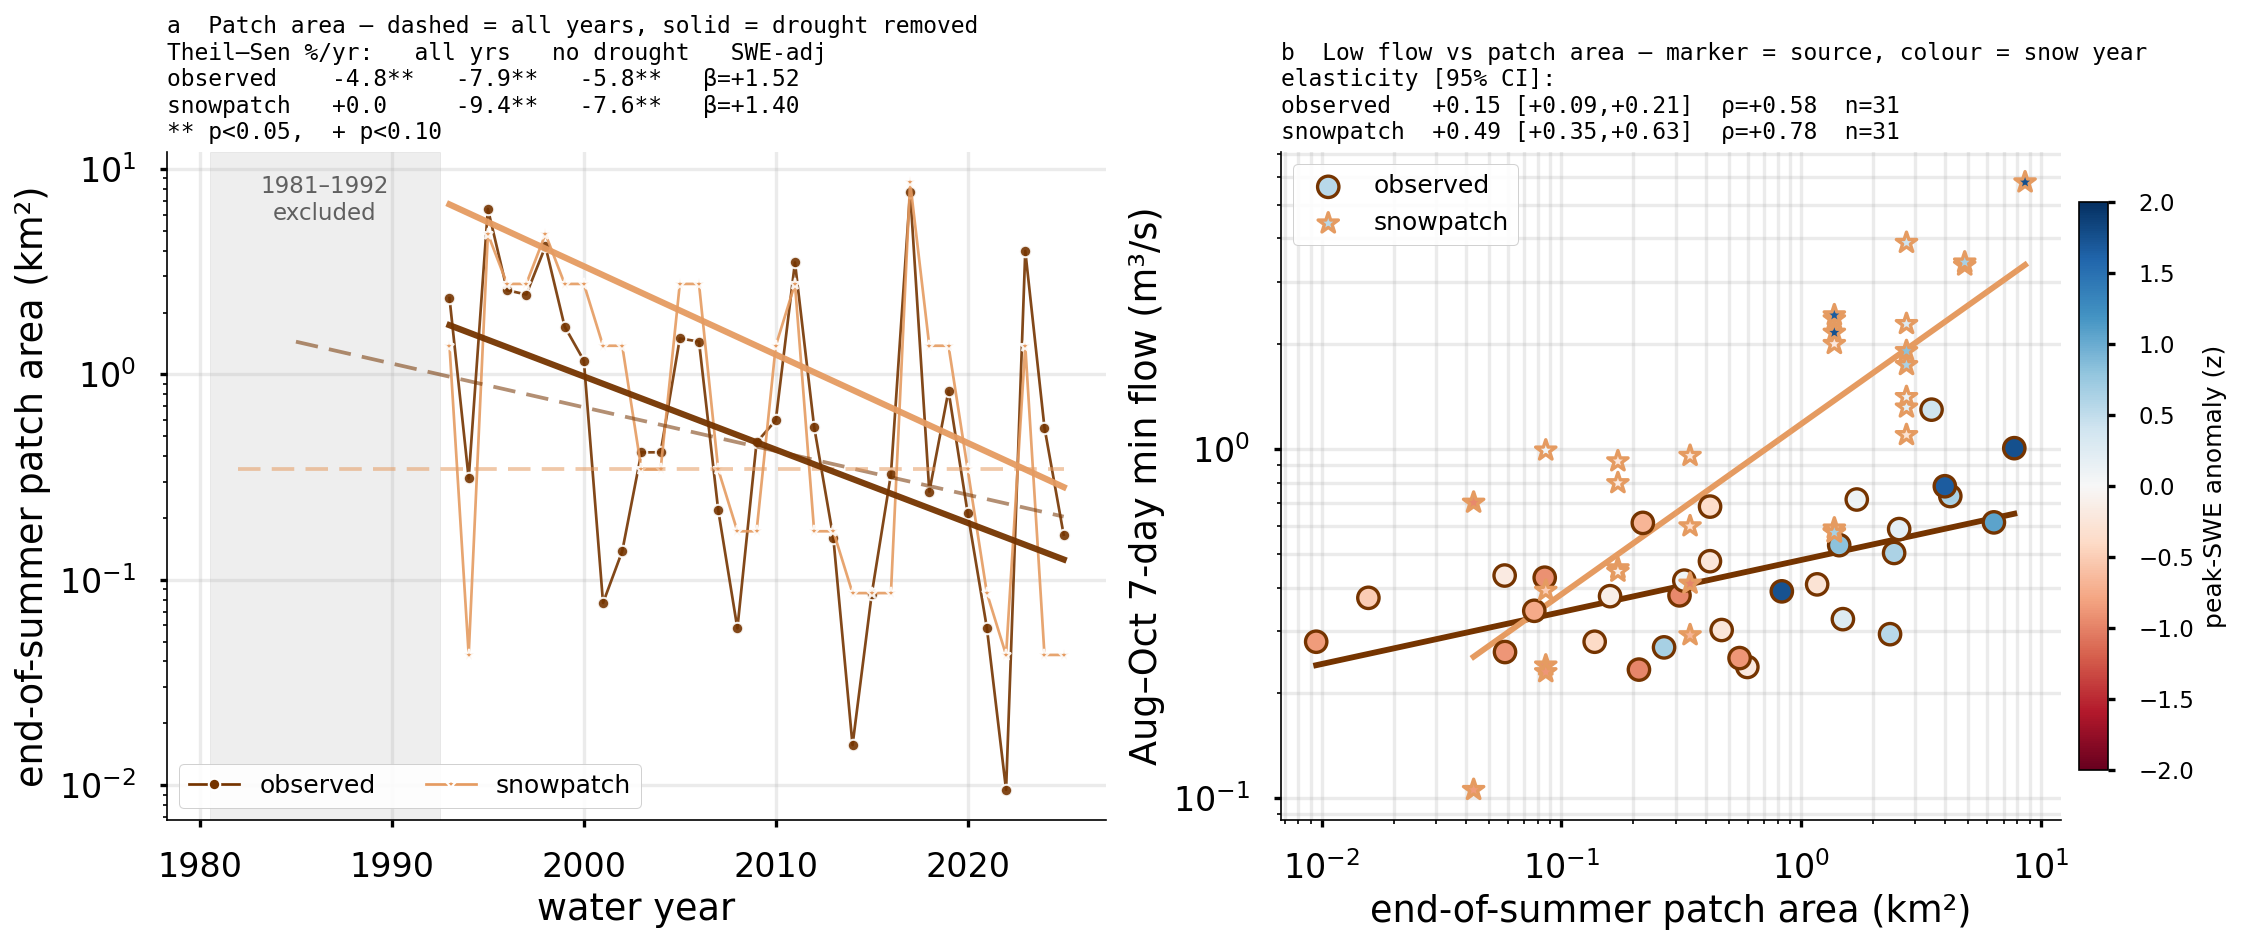

In [16]:
# ---- patch-area decline and its link to low flow, modelled vs observed ----------------
# Implementation lives in ess-project/utils/snowpatch_decline_fig.py so the figure can be
# regenerated outside the notebook. DROUGHT_YEARS are dropped from every fit and statistic
# but still drawn hollow; pass show_dropped=False to hide them entirely.
import sys as _sys
_U = "/home/dlhogan/projects/forked-repos/CONFLUENCE-uwmtnhydro/ess-project/utils"
if _U not in _sys.path:
    _sys.path.insert(0, _U)
import importlib
import snowpatch_decline_fig as _sdf
importlib.reload(_sdf)

DROUGHT_YEARS = (1981, 1992)
_sdf.main(DROUGHT_YEARS, show_dropped=False)

In [17]:
# ---- observed Tuolumne trends, one series per panel, normalised to the median -----------
# Implementation in ess-project/utils/snowpatch_trend_fig.py. Four OBSERVED series, no model:
# Landsat patch area, HH Aug-Oct 7-day min flow, DAN pillow peak SWE, TUM gauge WY precip.
#
# NORMALISED BY THE MEDIAN -> every panel centred on 1.0, so the four are comparable in
# relative terms despite four different units. Median in native units is in each legend.
#
# THE WEDGE AND THE DOTTED LINE SHARE AN ANCHOR, WHICH MAKES THE FIGURE A TEST. The wedge
# traces  anchor + b*(x - x_mid)  for b across the slope bounds, so the flat line at the
# anchor sits INSIDE the wedge exactly when the slope interval contains zero:
#     wedge swallows the dotted line -> no significant trend
#     wedge clears it                -> significant at this confidence level
# The anchor is the MEDIAN (the right partner for Theil-Sen -- both median-based), which
# normalisation puts at 1.0. NB this is the Theil-Sen SLOPE interval, a different test from
# the Spearman/Mann-Kendall p printed below; they usually agree, near the boundary they need not.
#
# PATCH AREA AND LOW FLOW ON LOG AXES -- both strongly right-skewed (patch spans 0.02x-16x its
# median), and on a linear axis the spike years own the panel. SWE and precip stay linear from 0.
#
# BLACK ONLY: solid = observations, dashed = Theil-Sen trend, dotted = median, grey = slope CI.
# Window runs to WY2025; series are NOT padded -- low flow stops at WY2023 (yr_low is capped
# there, obs is NaN at 2024) and TUM precip at WY2024.
import sys as _sys
_U = "/home/dlhogan/projects/forked-repos/CONFLUENCE-uwmtnhydro/ess-project/utils"
if _U not in _sys.path:
    _sys.path.insert(0, _U)
import importlib
import snowpatch_trend_fig as _stf
importlib.reload(_stf)

_stf.main(y0=1993, y1=2025, ci=0.95);


wrote /home/dlhogan/projects/forked-repos/CONFLUENCE-uwmtnhydro/ess-project/figures/draft/snowpatch_trends.png  WY1993-2025  CI=95%
  patch    -7.88 %/yr [ -12.43,  -1.53]  CI EXCLUDES 0  p=0.038  MK p=0.026  n=33
  flow     -1.35 %/yr [  -2.95,  +0.72]  includes 0     p=0.164  MK p=0.145  n=31
  swe      -0.83 %/yr [  -2.44,  +0.45]  includes 0     p=0.160  MK p=0.168  n=33
  ppt      -0.61 %/yr [  -2.00,  +0.86]  includes 0     p=0.548  MK p=0.551  n=32


In [18]:
import sys
REPO = Path("/home/dlhogan/projects/forked-repos/CONFLUENCE-uwmtnhydro")
sys.path.insert(0, str(REPO/"ess-project/utils"))
import trend_acf_summary as T
import lowflow_acf as L
from patch_swe import peak_swe_index
import pingouin as pg
import scipy.stats as stats

ns = T.notebook_ns(fast=True);
yr_low = ns["yr_low"]

eos = pd.read_csv(T.SCRATCH/"geospatial-data/snowpatch_fsca/eos_final.csv").set_index("year")
SNOW = (T.SCRATCH/"domain_Tuolumne_River_distributed_elevAspect/simulations"
                    "/snowpatch_anchor_20260812/anchor_m080")


In [19]:

area = {"observed": np.log(eos["A_shadow"].dropna()),
        "snowpatch": np.log(T.modelled_patch_area(SNOW, SNOW/"bin_spec.csv").dropna())}
swe_idx = peak_swe_index().dropna()
flow = {"observed": np.log(yr_low(ns["tuolumne_obs_augoct_low_flow"]).dropna()),
        "snowpatch": np.log(yr_low(ns["tuolumne_adj_augoct_low_flow"]).dropna())}
swe = pd.read_csv("/scratch/dlhogan/ess-project-data/geospatial-data/snowpatch_fsca/dan_peak_swe.csv", index_col=0, comment='#')['peak_swe_mm'].dropna()
temperature = ao_forcing["Tuolumne_tair_C"].dropna()

df = pd.DataFrame({
    "area_observed": area["observed"],
    "area_snowpatch": area["snowpatch"],
    "swe_idx": swe,
    "flow_observed": flow["observed"],
    "flow_snowpatch": flow["snowpatch"],
    "swe": swe,
    "temperature": temperature
})
df['wy'] = df.index


In [20]:

def spearmanr(x, y):
    rho = np.corrcoef(x.rank(), y.rank())[0, 1]
    n = len(x)
    t = rho * np.sqrt((n - 2) / (1 - rho**2))
    p = 2 * (1 - stats.t.cdf(abs(t), df=n - 2))
    return rho, p

In [21]:
# lag area only and correlate with flow_observed
spearmanr(df['area_observed'].loc[1993:2023], df['flow_observed'].shift(1).loc[1993:2023])

# # shift_df = df.copy()
shift_df['flow_observed'] = df['flow_observed'].shift(1)
shift_df['flow_snowpatch'] = df['flow_snowpatch'].shift(1)
shift_df['swe_shift'] = df['swe'].shift(1)

NameError: name 'shift_df' is not defined

In [ ]:
import pingouin as pg
start, end = 1993, 2023
mod_areaSnowpatch_swe_WY_temp = pg.partial_corr(data=shift_df.loc[start:end], x="area_snowpatch", y="flow_snowpatch", covar=["swe","wy","temperature"], method="spearman")
mod_sweSnowpatch_area_WY_temp = pg.partial_corr(data=shift_df.loc[start:end], x="swe", y="flow_snowpatch", covar=["area_snowpatch","wy","temperature"], method="spearman")

mod_areaSnowpatch_swe_temp = pg.partial_corr(data=shift_df.loc[start:end], x="area_snowpatch", y="flow_snowpatch", covar=["swe","temperature"], method="spearman")
mod_sweSnowpatch_area_temp = pg.partial_corr(data=shift_df.loc[start:end], x="swe", y="flow_snowpatch", covar=["area_snowpatch","temperature"], method="spearman")

mod_areaSnowpatch_swe = pg.partial_corr(data=shift_df.loc[start:end], x="area_snowpatch", y="flow_snowpatch", covar=["swe",], method="spearman")
mod_sweSnowpatch_area = pg.partial_corr(data=shift_df.loc[start:end], x="swe", y="flow_snowpatch", covar=["area_snowpatch",], method="spearman")

obs_areaObserved_swe_WY_temp = pg.partial_corr(data=shift_df.loc[start:end], x="area_observed", y="flow_observed", covar=["swe","wy","temperature"], method="spearman")
obs_sweObserved_area_WY_temp = pg.partial_corr(data=shift_df.loc[start:end], x="swe", y="flow_observed", covar=["area_observed","wy","temperature"], method="spearman")

obs_areaObserved_swe_temp = pg.partial_corr(data=shift_df.loc[start:end], x="area_observed", y="flow_observed", covar=["swe","temperature"], method="spearman")
obs_sweObserved_area_temp = pg.partial_corr(data=shift_df.loc[start:end], x="swe", y="flow_observed", covar=["area_observed","temperature"], method="spearman")

obs_areaObserved_swe = pg.partial_corr(data=shift_df.loc[start:end], x="area_observed", y="flow_observed", covar=["swe",], method="spearman")
obs_sweObserved_area = pg.partial_corr(data=shift_df.loc[start:end], x="swe", y="flow_observed", covar=["area_observed",], method="spearman")

temp_flow_wyArea = pg.partial_corr(data=shift_df.loc[start:end], x="temperature", y="flow_observed", covar=["wy",], method="spearman")

result_shift_df = pd.concat([
                    mod_areaSnowpatch_swe_WY_temp,
                    mod_sweSnowpatch_area_WY_temp,
                    mod_areaSnowpatch_swe_temp,
                    mod_sweSnowpatch_area_temp,
                    mod_areaSnowpatch_swe,
                    mod_sweSnowpatch_area,
                    obs_areaObserved_swe_WY_temp,
                    obs_sweObserved_area_WY_temp,
                    obs_areaObserved_swe_temp,
                    obs_sweObserved_area_temp,
                    obs_areaObserved_swe,
                    obs_sweObserved_area,
                    temp_flow_wyArea], keys=[
                        "model + area v. flow - swe,wy,temp",
                        "model + swe v. flow - area,wy,temp",
                        "model + area v. flow - swe,temp",
                        "model + swe v. flow - area,temp",
                        "model + area v. flow - swe",
                        "model + swe v. flow - area",
                        "obs + area v. flow - swe,wy,temp",
                        "obs + swe v. flow - area,wy,temp",
                        "obs + area v. flow - swe,temp",
                        "obs + swe v. flow - area,temp",
                        "obs + area v. flow - swe",
                        "obs + swe v. flow - area",
                        "temp v. flow - wy,"
                    ], axis=0)
result_shift_df

,,n,r,CI95,p_val
"model + area v. flow - swe,wy,temp",spearman,31,0.488662,"[0.14, 0.73]",8.325843e-03
"model + swe v. flow - area,wy,temp",spearman,31,0.874477,"[0.74, 0.94]",1.187712e-09
"model + area v. flow - swe,temp",spearman,31,0.527469,"[0.2, 0.75]",3.277812e-03
"model + swe v. flow - area,temp",spearman,31,0.878065,"[0.75, 0.94]",3.910165e-10
model + area v. flow - swe,spearman,31,0.405517,"[0.05, 0.67]",2.620012e-02
model + swe v. flow - area,spearman,31,0.860593,"[0.73, 0.93]",1.071111e-09
"obs + area v. flow - swe,wy,temp",spearman,31,0.136050,"[-0.25, 0.48]",4.900014e-01
"obs + swe v. flow - area,wy,temp",spearman,31,0.503048,"[0.16, 0.74]",6.361211e-03
"obs + area v. flow - swe,temp",spearman,31,0.193066,"[-0.19, 0.52]",3.156491e-01
"obs + swe v. flow - area,temp",spearman,31,0.541508,"[0.22, 0.76]",2.415547e-03


In [ ]:
r_swe_flow, p_swe_flow = spearmanr(swe.loc[1989:2023], flow["observed"].shift(1).loc[1989:2023])
r_swe_area, p_swe_area = spearmanr(swe.loc[1989:2023], area["observed"].loc[1989:2023])
r_area_flow, p_area_flow = spearmanr(area["observed"].loc[1989:2023], flow["observed"].shift(1).loc[1989:2023])
r_temp_flow, p_temp_flow = spearmanr(temperature.shift(1).loc[1989:2023], area["observed"].loc[1989:2023])

r_flow_area_swe = (r_area_flow - (r_swe_flow * r_swe_area))/(np.sqrt((1-r_swe_flow**2) * (1-r_swe_area**2)))
r_flow_swe_area = (r_swe_flow - (r_area_flow * r_swe_area))/(np.sqrt((1-r_area_flow**2) * (1-r_swe_area**2)))

r_swe_modflow, p_swe_modflow = spearmanr(swe.loc[1989:2023], flow["snowpatch"].loc[1989:2023])
r_swe_modarea, p_swe_modarea = spearmanr(swe.loc[1989:2023], area["snowpatch"].loc[1989:2023])
r_modarea_modflow, p_modarea_modflow = spearmanr(area["snowpatch"].loc[1989:2023], flow["snowpatch"].loc[1989:2023])

r_modflow_modarea_swe = (r_modarea_modflow - (r_swe_modflow * r_swe_modarea))/(np.sqrt((1-r_swe_modflow**2) * (1-r_swe_modarea**2)))
r_modflow_swe_modarea = (r_swe_modflow - (r_modarea_modflow * r_swe_modarea))/(np.sqrt((1-r_modarea_modflow**2) * (1-r_swe_modarea**2)))

def p_val(r, n):
    t_stat = r * np.sqrt((n - 2) / (1 - r**2))
    p_value = 2 * (1 - stats.t.cdf(abs(t_stat), df=n - 2))
    return p_value


print(f"Partial correlation between observed snowpatch area and low flow, controlling for SWE: r = {r_flow_area_swe:.3f}, p = {p_val(r_flow_area_swe, len(swe.loc[1989:2023])):.3f}")
print(f"Partial correlation between observed snowpatch low flow and SWE, controlling for area: r = {r_flow_swe_area:.3f}, p = {p_val(r_flow_swe_area, len(swe.loc[1989:2023])):.3f}")
print(f"Spearman correaltion between observed snowpatch area and SNOTEL SWE: r = {r_swe_area:.3f}, p = {p_swe_area:.3f}")
print(f"Spearman correaltion between observed snowpatch low flow and SNOTEL SWE: r = {r_swe_flow:.3f}, p = {p_swe_flow:.3f}")
print(f"Spearman correaltion between observed snowpatch area and low flow: r = {r_area_flow:.3f}, p = {p_area_flow:.3f}")
print("----------------------------------")

print(f"Partial correlation between model snowpatch area and low flow, controlling for SWE: r = {r_modflow_modarea_swe:.3f}, p = {p_val(r_modflow_modarea_swe, len(swe.loc[1989:2023])):.3f}")
print(f"Partial correlation between model snowpatch low flow and SWE, controlling for area: r = {r_modflow_swe_modarea:.3f}, p = {p_val(r_modflow_swe_modarea, len(swe.loc[1989:2023])):.3f}")
print(f"Spearman correaltion between model snowpatch area and SNOTEL SWE: r = {r_swe_modarea:.3f}, p = {p_swe_modarea:.3f}")
print(f"Spearman correaltion between model snowpatch low flow and SNOTEL SWE: r = {r_swe_modflow:.3f}, p = {p_swe_modflow:.3f}")
print(f"Spearman correaltion between model snowpatch area and low flow: r = {r_modarea_modflow:.3f}, p = {p_modarea_modflow:.3f}")



Partial correlation between observed snowpatch area and low flow, controlling for SWE: r = 0.226, p = 0.192
Partial correlation between observed snowpatch low flow and SWE, controlling for area: r = -0.122, p = 0.486
Spearman correaltion between observed snowpatch area and SNOTEL SWE: r = 0.760, p = 0.000
Spearman correaltion between observed snowpatch low flow and SNOTEL SWE: r = 0.080, p = 0.650
Spearman correaltion between observed snowpatch area and low flow: r = 0.207, p = 0.233
----------------------------------
Partial correlation between model snowpatch area and low flow, controlling for SWE: r = 0.362, p = 0.033
Partial correlation between model snowpatch low flow and SWE, controlling for area: r = 0.606, p = 0.000
Spearman correaltion between model snowpatch area and SNOTEL SWE: r = 0.715, p = 0.000
Spearman correaltion between model snowpatch low flow and SNOTEL SWE: r = 0.811, p = 0.000
Spearman correaltion between model snowpatch area and low flow: r = 0.728, p = 0.000


## 7 · Long-term storage feature impacts on low flows

If the memory signatures in the ACF and the drainage timescales in the MRC are real, **how much
late-season water actually depends on the store?** That is a magnitude question, and the two
statistics below answer different halves of it.

**Partial correlation** — does the store→low-flow link survive holding the confounds fixed? This is
the test against the obvious objection, *"the patch is just a proxy for a big snow year."* It gives a
yes/no, not a size.

**Elasticity** — the slope of log(low flow) on log(store), i.e. **what % change in low flow follows a
1 % change in the store**, net of the same controls. This is what the discussion needs: a correlation
cannot support "when the store is removed, water goes away."

Confounds are **peak SWE** and **Aug–Oct air temperature**. They are not the same kind of control:
peak SWE is an *upstream cause* of the store (removing it asks what the store adds *beyond* the snow
year — deliberately conservative), while temperature is the candidate *common cause* of both store
and flow. Temperature turns out to add nothing in either basin, for different reasons the cell
prints and explains.

For the Tuolumne, **both worlds use the same observed control** — `dan_peak_swe.csv`, the Dana
Meadows daily pillow peak (Feb–May max), raw and unmixed — so the model is asked the same
question with the same yardstick as the observations. The East has no observed analogue and uses
modelled basin peak SWE.

⚠️ **This replaces `peak_swe_index()`, and the choice is load-bearing.** That index folds in TUM,
whose pillow failed in 2011 (430 mm against a 991 mm snow course and 1031 mm at DAN, in a record
year) and in 2016 (71 negative readings). A snow control that under-reports in a big-patch year
cannot remove that year's patch signal, and the residue reappears as "independent" patch
information. Using DAN moves the observed partial from **+0.34 (p=0.06) to +0.20 (p=0.28)**.

| | Tuolumne | East |
|---|---|---|
| store | end-of-summer patch area | aquifer storage on 1 Oct |
| response | Aug–Oct 7-day min flow | Sep–Nov 7-day min flow |
| timing | contemporaneous | **lagged** — storage of year *Y*−1 → low flow of year *Y* |
| observed counterpart | **yes** (Landsat) | **no** — model vs model only |
| window | WY1993–2023 (Landsat start; HH record ends) | WY1982–2024 |

The asymmetry is forced by observability, not by choice: aquifer storage has no observed analogue, so
the East rows can only show that *adding* a store creates a carryover the baseline lacks. The
Tuolumne rows are the ones carrying the anti-circularity argument, because there the same quantity
exists in both worlds.

Cells above (`43ea48e2`–`11203e1d`) are the partial-correlation half of this same section; the
heading may be worth moving up above them.

In [ ]:
# ---- does the STORE itself move the low flow, once the snow year is held fixed? ----------
# Two questions, deliberately separated, because they answer different things:
#
#   partial rho   DOES the link survive control?   rank association, no units, no magnitude
#   elasticity    HOW BIG is it?                   d ln(Q_low) / d ln(X): % flow per % store
#


from scipy.stats import rankdata, t as _tdist, pearsonr as _pearson
from scipy.stats import spearmanr as _spearman        # NB cell a0ca8a2d shadows scipy's

_PANEL_CSV = DATA/"store_lowflow_elasticity.csv"
Y0, Y1 = 1989, 2023                       # 2024 drops itself, see note above


def elasticity(y, x, covars, n_boot=2000, block=3, seed=0):
    """OLS of log(y) on log(x) + covars; the log-log slope IS the elasticity.

    CI is a moving-block bootstrap, not the OLS/HC3 interval: both series are strongly
    autocorrelated (that is the point of the paper), so the iid standard error is too narrow.
    block=3 yr is a compromise -- long enough to carry the year-to-year persistence, short
    enough to leave ~10 independent blocks in a 31-year record."""
    D = pd.concat([np.log(y.rename("ly")), np.log(x.rename("lx"))]
                  + [c.rename(f"z{i}") for i, c in enumerate(covars)], axis=1).dropna()
    X = sm.add_constant(D.drop(columns="ly"))
    m = sm.OLS(D["ly"], X).fit(cov_type="HC3")
    n, nb = len(D), int(np.ceil(len(D)/block))
    Xv, yv = np.asarray(X, float), np.asarray(D["ly"], float)
    j = list(X.columns).index("lx")
    rng = np.random.default_rng(seed)
    idx = (rng.integers(0, n-block+1, size=(n_boot, nb))[:, :, None]
           + np.arange(block)[None, None, :]).reshape(n_boot, -1)[:, :n]
    bs = np.array([np.linalg.lstsq(Xv[i], yv[i], rcond=None)[0][j] for i in idx])
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return dict(b=m.params["lx"], lo=lo, hi=hi, n=n)


def partial_rho(x, y, covars):
    """Partial SPEARMAN: rank-transform everything, project the controls out of BOTH, then take
    the PEARSON correlation of the residuals.

    Pearson, not Spearman, on that last step -- this is the definition, and it is what the
    first-order formula in cell 11203e1d and pingouin's partial_corr(method="spearman") both
    return. Taking Spearman of the residuals re-ranks an already-ranked quantity and
    attenuates the estimate (+0.30 instead of +0.34 for observed Tuolumne area~flow | SWE)."""
    D = pd.concat([x.rename("x"), y.rename("y")]
                  + [c.rename(f"z{i}") for i, c in enumerate(covars)], axis=1).dropna()
    R = D.apply(rankdata)
    Z = sm.add_constant(R.drop(columns=["x", "y"]))
    ex = R["x"] - sm.OLS(R["x"], Z).fit().fittedvalues
    ey = R["y"] - sm.OLS(R["y"], Z).fit().fittedvalues
    r = _pearson(ex, ey)[0]
    dof = len(D) - 2 - (Z.shape[1] - 1)
    tt = r*np.sqrt(dof/max(1-r**2, 1e-12))
    return dict(r=r, p=2*(1-_tdist.cdf(abs(tt), dof)), n=len(D))


# TEMPERATURE SOURCE: Aug-Oct basin-mean airtemp, BOTH basins -- one common late-summer season
# so the two are comparable, even though East's low-flow window is Sep-Nov.
#
# NOT `ao_forcing` (cell aoforcing), which is the same season but bins with wy = y + (m>=10):
# that puts October in the PREVIOUS label year, a one-year offset on the month that matters
# most for the late-season minimum, while the low-flow series bin by CALENDAR year.
# basin_lowflow_season_tair.csv is the same computation with calendar-year binning.
_tair = pd.read_csv(DATA/"basin_lowflow_season_tair.csv", index_col="year")

# ---- Tuolumne: end-of-summer patch area -> Aug-Oct 7-day min flow ------------------------
# BOTH worlds are controlled with the SAME observed series so the model is asked the same
# question with the same yardstick. That series is dan_peak_swe.csv -- DAN (Dana Meadows) CDEC
# daily pillow, Feb-May max, 0 < v < 80 in, RAW. One station, no cross-station patching.
#
# WHY DAN AND NOT peak_swe_index(): the multi-site index takes the pillows as-is, and TUM
# (Tuolumne Meadows) contributes two broken station-years to it:
#     TUM 2011  pillow peaks 430 mm on 19 Feb then declines, while its own snow course reads
#               991 mm on 28 Mar and DAN reads 1031 mm -- a record Sierra year. It failed.
#     TUM 2016  71 negative Feb-May readings (offset to -23.8 in); no usable pillow data at all.
# DAN has neither problem: every water year 1993-2023 has usable Feb-May data and negatives are
# trivial (6 days in 2008, <=3 elsewhere).
#
# THAT MATTERS MORE THAN IT SOUNDS. A control that under-reports snow in a big-patch year cannot
# remove that year's patch signal, and the un-removed signal reappears as "independent" patch
# information. Using DAN instead of the TUM-contaminated index moves the observed partial from
# +0.34 to +0.20 -- see the product comparison at the bottom, where every properly-QA'd observed
# snow product lands at +0.12..+0.20 and only peak_swe_index() sits outside that band.
#
# DAN'S OWN WEAK YEAR, left in deliberately: 1995 has only 23 valid Feb-May days and the gap
# straddles the peak, so its 774 mm is likely low. It is NOT patched from TUM -- this control is
# one station, measured, unmixed. tuolumne_peak_swe_index.csv holds the patched 2-site
# alternative if a sensitivity is wanted (it gives obs +0.13 rather than +0.20).
#
# NB these controls all correlate at rho >= 0.87 with each other yet give partials from +0.12 to
# +0.34. The partial is a small difference between two larger numbers (r_AQ - r_AS*r_QS), so it
# is badly conditioned when the control is ~0.8 correlated with the predictor, which it is here.
# Highly similar controls need not agree.
_tuo = pd.DataFrame({
    "A_obs":   eos["A_shadow"],
    "A_mod":   T.modelled_patch_area(SNOW, SNOW/"bin_spec.csv"),
    "Q_obs":   yr_low(ns["tuolumne_obs_augoct_low_flow"]).shift(1),
    "Q_mod":   yr_low(ns["tuolumne_adj_augoct_low_flow"]).shift(1),
    "swe_obs": pd.read_csv(DATA/"dan_peak_swe.csv", comment="#",
                           index_col="water_year")["peak_swe_mm"],
    "swe_mod": pd.read_csv(DATA/"dan_peak_swe.csv", comment="#",
                           index_col="water_year")["peak_swe_mm"],
    "tair":    _tair["Tuolumne_tair_C"],
}).loc[Y0:Y1]
_tuo["yr"] = _tuo.index

# ---- East: aquifer storage on 1 Oct -> the FOLLOWING Sep-Nov low flow --------------------
# The lag is the whole point and it is one-directional: storage is read on 1 Oct of year Y-1
# (the state the basin carries INTO water year Y) and the response is the Sep-Nov minimum of
# year Y, ~11 months later. Nothing on the right-hand side post-dates the response, which is
# the only hard rule a mixed-lag partial correlation has to obey.
#
# The control is year-Y peak SWE, i.e. the snow year that happens AFTER the storage is read.
# That is deliberate: it blocks the one path that would make the lag spurious (a wet year
# followed by another wet year) WITHOUT removing the mechanism, because storage's whole job
# is to integrate the PRIOR year's water. Controlling on year Y-1 climate instead would
# residualise the store against its own recharge and delete the signal being tested.
_aq = pd.read_csv(DATA/"east_aquifer_oct1.csv", index_col="oct1_year")
_slowQ = pd.read_csv(T.SCRATCH/"streamflow-data/EastRiver"
                     "/EastRiver_SUMMA_slowstore_sf10b2p5_dailyDischarge_1981_2025.csv",
                     parse_dates=["time"]).set_index("time")["discharge"]
_east = pd.DataFrame({
    "Q_base": yr_low(ns["east_mod_augoct_low_flow"]).shift(1),
    "Q_slow": yr_low(_slowQ.where(_slowQ.index.month.isin([9, 10, 11]))
                     .rolling(7, center=True, min_periods=7).mean().resample("YE-DEC").min()).shift(1),
    # Butte SNOTEL (NRCS 380, 3106 m) Feb-May peak -- OBSERVED, matching the Tuolumne's DAN,
    # so both basins condition on the same kind of measurement. The modelled basin mean gives
    # e=+0.43 (p=0.068) vs +0.40 (p=0.110) here: same estimate, wider CI, because one pillow
    # is a noisier proxy for basin-mean snow. rho(Butte, modelled basin) = +0.875, n=44.
    "swe":    mod_basin_peak_swe['East'].shift(1),
    "tair":   _tair["East_tair_C"],
}).loc[1986:2025]
_east["S_base"] = _aq["baseline_store"].reindex(_east.index).values      # 1 Oct, PRIOR yr
_east["S_slow"] = _aq["slowstore_store"].reindex(_east.index).values
_east["yr"] = _east.index

_rows = []
for _basin, _d, _sets in (
    ("Tuolumne", _tuo, [("observed",   "A_obs", "Q_obs", "swe_obs"),
                        ("snowpatch",  "A_mod", "Q_mod", "swe_obs")]),
    ("East",     _east, [("baseline",  "S_base", "Q_base", "swe"),
                         ("slow store", "S_slow", "Q_slow", "swe")]),
):
    for _tag, _x, _y, _s in _sets:
        for _cn, _cv in (("none", []), ("peak SWE", [_d[_s]]),
                         ("peak SWE + temp", [_d[_s], _d["tair"]])):
            _e = elasticity(_d[_y], _d[_x], _cv)
            _p = partial_rho(_d[_x], _d[_y], _cv)
            _rows.append(dict(basin=_basin, series=_tag, controls=_cn, n=_e["n"],
                              partial_rho=_p["r"], p=_p["p"],
                              elasticity=_e["b"], ci_lo=_e["lo"], ci_hi=_e["hi"]))
store_elasticity = pd.DataFrame(_rows)
store_elasticity.to_csv(_PANEL_CSV, index=False)

print("STORE -> LOW FLOW.  partial rho = does it survive control; elasticity = % flow per % store")
print(f"Tuolumne WY{Y0}-{int(_tuo['Q_obs'].dropna().index.max())} (patch area, contemporaneous)   "
      f"East WY1982-2024 (aquifer storage on 1 Oct, lagged into the NEXT low-flow season)\n")
print(store_elasticity.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))

print("\n  why temperature does not move the table (Spearman):")
for _b, _d, _x, _s in (("Tuolumne obs", _tuo, "A_obs", "swe_obs"),
                       ("East slow   ", _east, "S_slow", "swe")):
    _y = "Q_obs" if _b.startswith("Tuo") else "Q_slow"
    _p = lambda a, c: _spearman(*_d[[a, c]].dropna().values.T)[0]
    print(f"    {_b}  store~temp {_p(_x,'tair'):+.2f}   flow~temp {_p(_y,'tair'):+.2f}   "
          f"SWE~temp {_p(_s,'tair'):+.2f}   store~SWE {_p(_x,_s):+.2f}   flow~SWE {_p(_y,_s):+.2f}")

# trend guard: what the dropped `year` control would have done to the fully-controlled row
print("\n  with year added to peak SWE + temp (trend guard):")
for _b, _d, _sets in (("Tuolumne", _tuo, [("observed", "A_obs", "Q_obs", "swe_obs"),
                                          ("snowpatch", "A_mod", "Q_mod", "swe_mod")]),
                      ("East", _east, [("baseline", "S_base", "Q_base", "swe"),
                                       ("slow store", "S_slow", "Q_slow", "swe")])):
    for _tag, _x, _y, _s in _sets:
        _a = partial_rho(_d[_x], _d[_y], [_d[_s], _d["tair"]])
        _c = partial_rho(_d[_x], _d[_y], [_d[_s], _d["tair"], _d["yr"]])
        print(f"    {_b:8s} {_tag:10s}  rho {_a['r']:+.3f} (p={_a['p']:.3f})"
              f"  ->  {_c['r']:+.3f} (p={_c['p']:.3f}) with year")

# ---- how much does the choice of SWE control matter? ------------------------------------
# It matters a lot, and not in one direction, so it is reported rather than buried. Within a
# world, patch area and peak SWE share a generating process (rho 0.74-0.83 in BOTH worlds),
# so controlling a world with its OWN SWE removes more than controlling it with the other
# world's. Swapping the control moves the observed partial from +0.30 (n.s.) to +0.40 (p<0.05)
# and the modelled one from +0.13 (n.s.) to +0.56 (p<0.01) -- opposite directions.
#
# So: the SIGN and the ORDER of these partials are stable, the SIGNIFICANCE is not. Do not
# report a p-value from this table without also reporting which SWE product was the control.
print("\n  control-sensitivity check -- what the SWE control choice costs (Tuolumne):")
for _tag, _x, _y in (("observed", "A_obs", "Q_obs"), ("snowpatch", "A_mod", "Q_mod")):
    for _s in ("swe_obs", "swe_mod"):
        _p = partial_rho(_tuo[_x], _tuo[_y], [_tuo[_s]])
        _e = elasticity(_tuo[_y], _tuo[_x], [_tuo[_s]])
        print(f"    {_tag:9s} control={_s:8s}  rho={_p['r']:+.3f} (p={_p['p']:.3f})"
              f"   elasticity={_e['b']:+.3f} [{_e['lo']:+.3f}, {_e['hi']:+.3f}]")
print(f"\n    patch area vs peak SWE, Spearman:  "
      f"obs/obs {_spearman(*_tuo[['A_obs','swe_obs']].dropna().values.T)[0]:+.2f}   "
      f"mod/mod {_spearman(*_tuo[['A_mod','swe_mod']].dropna().values.T)[0]:+.2f}"
      f"   <- the control and the predictor are nearly the same variable")


STORE -> LOW FLOW.  partial rho = does it survive control; elasticity = % flow per % store
Tuolumne WY1989-2023 (patch area, contemporaneous)   East WY1982-2024 (aquifer storage on 1 Oct, lagged into the NEXT low-flow season)

   basin     series        controls  n  partial_rho      p  elasticity  ci_lo  ci_hi
Tuolumne   observed            none 35       +0.207 +0.233      +0.044 -0.048 +0.110
Tuolumne   observed        peak SWE 35       +0.226 +0.199      +0.119 -0.020 +0.303
Tuolumne   observed peak SWE + temp 35       +0.197 +0.271      +0.124 -0.022 +0.303
Tuolumne  snowpatch            none 35       +0.456 +0.006      +0.242 +0.027 +0.375
Tuolumne  snowpatch        peak SWE 35       +0.539 +0.001      +0.484 +0.093 +0.692
Tuolumne  snowpatch peak SWE + temp 35       +0.534 +0.001      +0.466 +0.088 +0.678
    East   baseline            none 38       +0.103 +0.539      +0.133 -0.213 +0.463
    East   baseline        peak SWE 38       +0.309 +0.063      +0.194 +0.022 +0.407
    East

In [ ]:
_east_shift = _east.copy()
_east_shift['Q_base'] = _east['Q_base'].shift(1)
_east_shift['Q_slow'] = _east['Q_slow'].shift(1)
_east_shift['swe'] = _east['swe'].shift(1)

spearmanr(_east_shift['S_base'].loc[1987:2024], _east_shift['Q_base'].loc[1987:2024])
# pg.partial_corr(data=_east_shift.loc[1987:2024], x="S_slow", y="Q_slow", covar=["swe"], method="spearman")
# pg.corr(_east_shift['S_slow'].loc[1987:2024], _east_shift['Q_slow'].loc[1987:2024], method="spearman")

(np.float64(0.07911150016413174), np.float64(0.6368366174950837))

### 7a · Elasticity drawn as a slope

`ess-project/utils/store_elasticity_fig.py`. Both axes are logged, so **a fitted slope *is* the
elasticity** — the reader measures ε off the page instead of taking it from a table.

The line through each cloud is the **SWE-controlled (partial) slope**, not the OLS fit to the
visible points: it is the coefficient on log *S* in log *Q* = α + ε log *S* + β log *W*, anchored at
that series' centroid so only the **angle** carries meaning, never the intercept. It is shallower
than the naked point cloud, because peak SWE is an upstream cause of patch area (ρ ≈ +0.75) and part
of the visible tilt is the snow year rather than the store. Drawing the raw fit would show a steeper
line than the number reported in the text.

| panel | question | answer |
|---|---|---|
| **a** Tuolumne, same year | does a bigger patch mean more flow *that* summer? | yes — obs ε = +0.11\*\*, model ε = +0.21\*\* |
| **b** Tuolumne, following year | does it mean more flow the *next* summer? | no — obs ε = +0.00, model ε = −0.05 |
| **c** East, lagged | does storage carried in raise the *next* autumn's minimum, and does the slow store create that where the baseline had none? | baseline ε = +0.03 (n.s.), slow store ε = +0.43\* |

Panels **a** and **b** share axes deliberately: the comparison is between two angles, and a slope only
looks like its value when both panels span the same log decades per unit of plot.

**Read a-vs-b as the headline.** Within a summer the patch is doing real work in both worlds, and the
model does about **2×** the work the observations show (+0.21 vs +0.11) — same sign, too much gain.
Across the winter it does none in either world: the patch that survives one summer tells you nothing
about the next summer's minimum. **c** is the counterfactual the Tuolumne cannot supply — a store
that *does* carry over, present only when it is built into the model.

⚠️ `TUO0` below is **1989**, not the 1993 Landsat-reliable start used in §7. Set `TUO0 = 1993` to
match, and expect the observed ε to move — the four extra years are early-record and low-confidence.


In [ ]:
# ---- elasticity as a log-log slope: patch/aquifer store vs late-season low flow -------
# Implementation lives in ess-project/utils/store_elasticity_fig.py. The line drawn is the
# SWE-CONTROLLED slope (coef on log S in  log Q = a + e log S + b log SWE), placed at each
# series' centroid -- so read the ANGLE, not the height. Windows are module constants; set
# them here before calling main() to explore alternatives (e.g. TUO0=1993, EAST0=1987).
import sys as _sys
_U = "/home/dlhogan/projects/forked-repos/CONFLUENCE-uwmtnhydro/ess-project/utils"
if _U not in _sys.path:
    _sys.path.insert(0, _U)
import importlib
import store_elasticity_fig as _sef
importlib.reload(_sef)

_sef.TUO0,  _sef.TUO1  = 1989, 2023      # Landsat-reliable start is 1993 -- see note above
_sef.EAST0, _sef.EAST1 = 1986, 2024      # 1982 keeps p<0.05 on the slow store; 1986 does not

_sef.main();


wrote /home/dlhogan/projects/forked-repos/CONFLUENCE-uwmtnhydro/ess-project/figures/draft/store_elasticity.png
  a_obs    ε=+0.106 (p=0.024)  ρ=+0.565  n=35
  a_mod    ε=+0.210 (p=0.013)  ρ=+0.728  n=35
  b_obs    ε=+0.095 (p=0.262)  ρ=+0.222  n=33
  b_mod    ε=+0.351 (p=0.015)  ρ=+0.383  n=33
  c_base   ε=-0.025 (p=0.887)  ρ=+0.019  n=38
  c_slow   ε=+0.335 (p=0.200)  ρ=+0.112  n=38


## 8 · How much of the late-season water comes from the patch?

The snowpatch HRU is 8.61 km2 — **1.11 % of the Tuolumne**. Over a whole water year it
delivers about that much of the runoff (1.8 %), so as a water source it is unremarkable.
What makes it matter is *when* it delivers: in Aug–Oct it supplies **8.3 % of the volume over
the whole record and ~15 % in a median year**, and in the driest years it supplies most of
the late-season flow outright.

The table below ranks water years by total annual runoff and shows the patch share at each
end, with the all-year median as the reference row.

**Caveat — this is `scalarSurfaceRunoff` only.** The run has `groundwatr = qTopmodl`, so
`scalarAquiferBaseflow` is identically zero and soil baseflow was never written to
`outputControl.txt`. Area-weighted surface runoff averages 1.607e-08 m/s against
`averageRoutedRunoff` at 1.981e-08, i.e. **19 % of the water is unaccounted for and cannot be
split per HRU from the saved output**. The patch is steep, thin-soiled, high terrain and
likely routes more of its water at the surface than the basin average, so treat these shares
as an upper bound. Adding `scalarTotalRunoff` to `outputControl.txt` and re-running
`anchor_m080` would close the budget exactly.

In [ ]:
# ---- share of Aug-Oct water produced by the snowpatch HRU ----------------------------
# Volume per HRU = scalarSurfaceRunoff (m/s) x HRUarea (m2) x 3600 s. See the caveat above:
# surface runoff is 81% of the routed total, so these shares are an upper bound.
# Cached -- the hourly netCDF is 385704 x 37. Delete the CSV to rebuild.
_SHARE_CSV = DATA/"snowpatch_augoct_share.csv"
if _SHARE_CSV.exists():
    patch_share = pd.read_csv(_SHARE_CSV, index_col="wy")
else:
    import xarray as xr
    _R = Path("/scratch/dlhogan/ess-project-data/domain_Tuolumne_River_distributed_elevAspect"
              "/simulations/snowpatch_anchor_20260812/anchor_m080")
    _ds = xr.open_dataset(_R/"output/anchor_m080_timestep.nc")
    _at = xr.open_dataset(_R/"attributes.nc")
    _bs = pd.read_csv(_R/"bin_spec.csv")
    _hid = np.asarray(_ds.hruId.values).ravel()
    _ar = pd.Series(np.asarray(_at["HRUarea"].values).ravel(),
                    index=np.asarray(_at["hruId"].values).ravel()).reindex(_hid).to_numpy(float)
    _t = pd.DatetimeIndex(_ds.time.values)
    _v = np.asarray(_ds["scalarSurfaceRunoff"].values)*_ar*3600.0        # m3/hr per HRU
    _ds.close()
    # all 10 bins reconstitute the original HRU 2; anchor+perennial bins are the store itself
    _ip = [i for i, h in enumerate(_hid) if h in _bs.hruId.tolist()]
    _is = [i for i, h in enumerate(_hid) if h in
           _bs.loc[_bs.regime.isin(["anchor", "perennial"]), "hruId"].tolist()]
    _wy = _t.year + (_t.month >= 10)
    _ao = _t.month.isin([8, 9, 10])
    _S = lambda a, mk: pd.Series(a[mk], index=_wy[mk]).groupby(level=0).sum()
    patch_share = pd.DataFrame({
        "ann_Mm3":   _S(_v.sum(1), np.ones(len(_t), bool))/1e6,
        "ao_Mm3":    _S(_v.sum(1), _ao)/1e6,
        "ao_patch":  _S(_v[:, _ip].sum(1), _ao)/1e6,
        "ao_store":  _S(_v[:, _is].sum(1), _ao)/1e6}).loc[1982:2025]
    patch_share["patch_pct"] = 100*patch_share.ao_patch/patch_share.ao_Mm3
    patch_share["store_pct"] = 100*patch_share.ao_store/patch_share.ao_Mm3
    patch_share["peakSWE_mm"] = mod_basin_peak_swe["Tuolumne"].reindex(patch_share.index)
    patch_share.index.name = "wy"
    patch_share.to_csv(_SHARE_CSV)

_o = patch_share.sort_values("ann_Mm3")
_med = patch_share.median()


def _row(lab, r):
    return (f"  {lab:>9s} {r['peakSWE_mm']:8.0f} {r['ann_Mm3']:9.1f} "
            f"{100*r['ann_Mm3']/_med['ann_Mm3']:7.0f}% {r['ao_Mm3']:9.2f} "
            f"{r['patch_pct']:9.1f} {r['store_pct']:9.1f}")


print("Tuolumne Aug-Oct water: how much comes from the 8.61 km2 snowpatch HRU (1.11% of basin)")
print(f"\n  {'WY':>9s} {'peakSWE':>8s} {'annual':>9s} {'vs':>8s} {'Aug-Oct':>9s} "
      f"{'patch':>9s} {'store':>9s}")
print(f"  {'':>9s} {'mm':>8s} {'Mm3':>9s} {'median':>8s} {'Mm3':>9s} {'% of AO':>9s} {'% of AO':>9s}")
print("  " + "-"*67)
print("  DRIEST 5")
for y, r in _o.head(5).iterrows():
    print(_row(str(int(y)), r))
print("  WETTEST 5")
for y, r in _o.tail(5).iloc[::-1].iterrows():
    print(_row(str(int(y)), r))
print("  " + "-"*67)
print(_row("MEDIAN", _med))

_d5, _w5 = _o.head(5).patch_pct.mean(), _o.tail(5).patch_pct.mean()
print(f"\n  driest-5 mean patch share {_d5:.1f}%   median year {_med['patch_pct']:.1f}%   "
      f"wettest-5 mean {_w5:.1f}%   ({_d5/_w5:.0f}x)")
print(f"  Spearman patch share vs annual runoff: "
      f"{patch_share.patch_pct.corr(patch_share.ann_Mm3, method='spearman'):+.2f}"
      f"   vs peak SWE: "
      f"{patch_share.patch_pct.corr(patch_share.peakSWE_mm, method='spearman'):+.2f}")
print(f"  whole record: patch = {100*patch_share.ao_patch.sum()/patch_share.ao_Mm3.sum():.1f}% "
      f"of Aug-Oct volume, {100*patch_share.ao_patch.sum()/patch_share.ann_Mm3.sum():.2f}% "
      f"of annual volume")

Tuolumne Aug-Oct water: how much comes from the 8.61 km2 snowpatch HRU (1.11% of basin)

         WY  peakSWE    annual       vs   Aug-Oct     patch     store
                  mm       Mm3   median       Mm3   % of AO   % of AO
  -------------------------------------------------------------------
  DRIEST 5
       2015      162      64.8      20%      0.09      74.8      72.4
       1987      250      72.0      22%      0.29      18.0      17.0
       2014      210      95.5      29%      0.46      30.9      30.0
       1988      300      96.3      30%      0.78      10.6      10.0
       2021      368     103.3      32%      0.14      94.9      88.2
  WETTEST 5
       2017     1471    1031.5     318%     97.15       4.9       0.4
       1982     1026     873.8     269%     22.44       4.0       3.3
       2023     1376     866.7     267%     38.63       5.5       1.6
       1983     1137     812.5     250%     44.36       4.9       2.2
       1995     1235     811.3     250%    125.1